In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
from itertools import combinations
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, TimeSeriesSplit

In [35]:
df = pd.read_csv('/Users/antonyjebafrancis/Downloads/full_ecommerce_data_541909.csv', encoding="ISO-8859-1", dtype={'CustomerID': str, 'InvoiceID': str})

df.head()



,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,568653,84816,DANISH ROSE BEDSIDE CABINET,3,01/21/2025 16:33,39.95,15869.0,United Kingdom
1,C579199,85184c,SET 4 VALENTINE DECOUPAGE HEART BOX,-5,06/04/2025 00:36,5.79,17889.0,United Kingdom
2,559912,21870,I CAN ONLY PLEASE ONE PERSON MUG,2,06/15/2025 01:17,1.25,16149.0,Denmark
3,545291,22403,MAGNETS PACK OF 4 VINTAGE LABELS,12,07/12/2025 17:22,0.42,16550.0,United Kingdom
4,581411,22217,T-LIGHT HOLDER HANGING LACE,3,02/06/2025 04:31,1.25,15153.0,United Kingdom


In [36]:
import pandas as pd


df = pd.read_csv('/Users/antonyjebafrancis/Downloads/full_ecommerce_data_541909.csv', encoding="ISO-8859-1", dtype={'CustomerID': str, 'InvoiceID': str})


df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  541909 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406900 non-null  object 
 7   Country      541909 non-null  object 
dtypes: float64(1), int64(1), object(6)
memory usage: 33.1+ MB


In [37]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135009
Country             0
dtype: int64

In [13]:
df = df.dropna(subset=['Description'])

In [15]:
df = df.dropna(subset=['CustomerID'])

In [38]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135009
Country             0
dtype: int64

In [39]:
df.duplicated().sum()
df = df.drop_duplicates()

In [40]:
df['CustomerID'] = df['CustomerID'].astype(str)

In [41]:
(df['Quantity'] <= 0).sum(), (df['UnitPrice'] <= 0).sum()

(np.int64(11974), np.int64(108))

In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  541909 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   541909 non-null  object 
 7   Country      541909 non-null  object 
dtypes: float64(1), int64(1), object(6)
memory usage: 33.1+ MB


In [43]:
df.describe()

,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,4.822009,7.951656
std,11.821251,196.479737
min,-9.000000,0.000000
25%,1.000000,1.250000
50%,2.000000,2.100000
75%,3.000000,4.130000
max,96.000000,11062.060000


In [44]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,568653,84816,DANISH ROSE BEDSIDE CABINET,3,2025-01-21 16:33:00,39.95,15869.0,United Kingdom
1,C579199,85184c,SET 4 VALENTINE DECOUPAGE HEART BOX,-5,2025-06-04 00:36:00,5.79,17889.0,United Kingdom
2,559912,21870,I CAN ONLY PLEASE ONE PERSON MUG,2,2025-06-15 01:17:00,1.25,16149.0,Denmark
3,545291,22403,MAGNETS PACK OF 4 VINTAGE LABELS,12,2025-07-12 17:22:00,0.42,16550.0,United Kingdom
4,581411,22217,T-LIGHT HOLDER HANGING LACE,3,2025-02-06 04:31:00,1.25,15153.0,United Kingdom


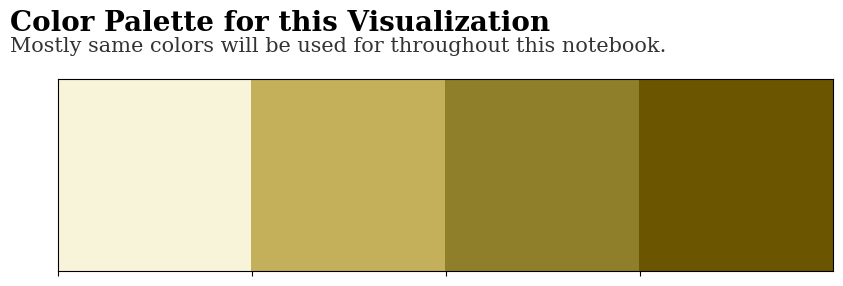

In [45]:
colors = ['#f8f4d9', '#c4b05a', '#8f7f2a', '#6b5500']
palette = sns.color_palette(palette=colors)

sns.palplot(palette, size=2.5)
plt.text(-0.75, -0.75, 'Color Palette for this Visualization', {'font': 'serif', 'size': 20, 'weight': 'bold'})
plt.text(-0.75, -0.64, 'Mostly same colors will be used for throughout this notebook.', {'font': 'serif', 'size': 15, 'weight': 'normal'}, alpha=0.8)
plt.show()

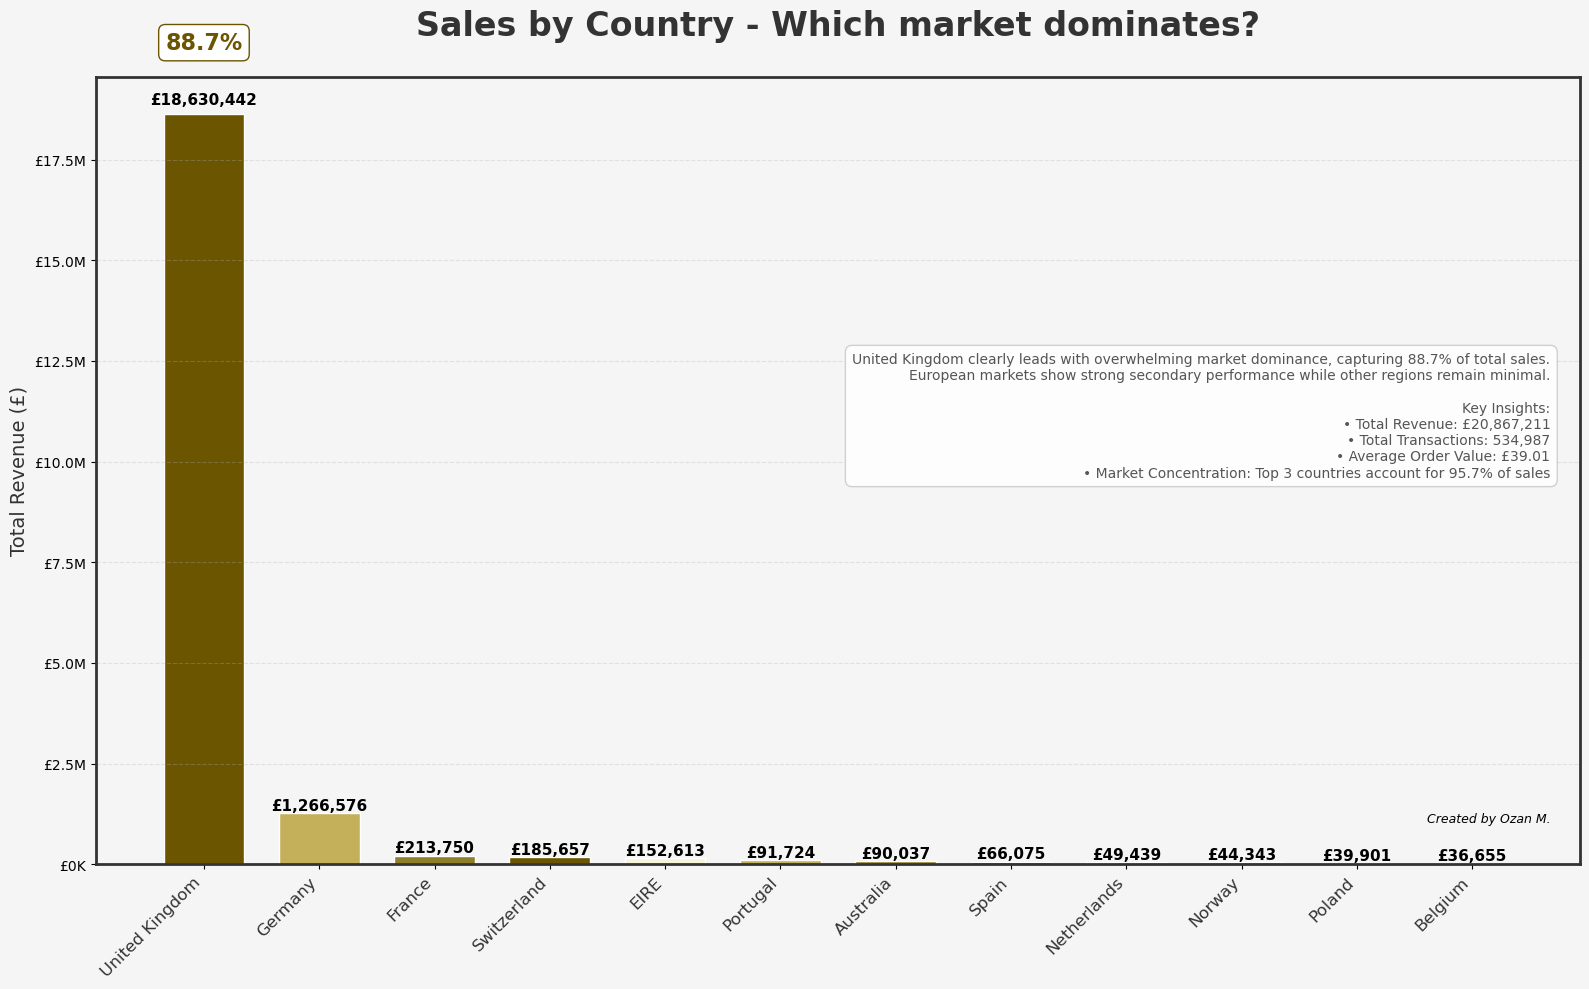

In [46]:
colors = ['#f8f4d9', '#c4b05a', '#8f7f2a', '#6b5500']


df['TotalAmount'] = df['Quantity'] * df['UnitPrice']


country_analysis = df.groupby('Country').agg({
    'TotalAmount': ['sum', 'count'],
    'Quantity': 'sum',
    'InvoiceNo': 'nunique'
}).round(2)

country_analysis.columns = ['TotalRevenue', 'TransactionCount', 'TotalQuantity', 'UniqueInvoices']
country_analysis['RevenuePercentage'] = (country_analysis['TotalRevenue'] / country_analysis['TotalRevenue'].sum() * 100).round(2)
country_analysis = country_analysis.sort_values('TotalRevenue', ascending=False)


top_countries = country_analysis.head(12)


plt.figure(figsize=(16, 10))
plt.style.use('default')


fig = plt.gcf()
fig.patch.set_facecolor('#f5f5f5')
ax = plt.gca()
ax.set_facecolor('#f5f5f5')


bars = plt.bar(range(len(top_countries)), 
               top_countries['TotalRevenue'], 
               color=[colors[3] if i == 0 else colors[i % len(colors)] for i in range(len(top_countries))],
               width=0.7,
               edgecolor='white',
               linewidth=1)


plt.title('Sales by Country - Which market dominates?', 
          fontsize=24, fontweight='bold', pad=30, color='#333')

plt.ylabel('Total Revenue (£)', fontsize=14, color='#333')
plt.xlabel('')


plt.xticks(range(len(top_countries)), top_countries.index, rotation=45, ha='right', fontsize=12, color='#333')


ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'£{x/1000000:.1f}M' if x >= 1000000 else f'£{x/1000:.0f}K'))


plt.grid(axis='y', alpha=0.3, linestyle='--')


for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + height*0.01,
             f'£{height:,.0f}', ha='center', va='bottom', fontweight='bold', fontsize=11)


highest_revenue = top_countries.iloc[0]['TotalRevenue']
highest_percentage = top_countries.iloc[0]['RevenuePercentage']
plt.text(0, highest_revenue + highest_revenue*0.08,
         f'{highest_percentage:.1f}%', ha='center', va='bottom', 
         fontweight='bold', fontsize=16, color='#6b5500',
         bbox=dict(boxstyle="round,pad=0.3", facecolor='white', edgecolor='#6b5500'))


analysis_text = f"""{top_countries.index[0]} clearly leads with overwhelming market dominance, capturing {top_countries.iloc[0]['RevenuePercentage']:.1f}% of total sales.
European markets show strong secondary performance while other regions remain minimal.

Key Insights:
• Total Revenue: £{top_countries['TotalRevenue'].sum():,.0f}
• Total Transactions: {top_countries['TransactionCount'].sum():,}
• Average Order Value: £{(top_countries['TotalRevenue'].sum() / top_countries['TransactionCount'].sum()):.2f}
• Market Concentration: Top 3 countries account for {top_countries.head(3)['RevenuePercentage'].sum():.1f}% of sales"""


plt.text(0.98, 0.65, analysis_text, transform=ax.transAxes, fontsize=10, color='#555',
         bbox=dict(boxstyle="round,pad=0.5", facecolor='white', alpha=0.9, edgecolor='#ccc'),
         verticalalignment='top', horizontalalignment='right')


plt.text(0.98, 0.05, 'Created by Ozan M.', transform=ax.transAxes, 
         fontsize=9, color='#000000', style='italic',
         verticalalignment='bottom', horizontalalignment='right')


plt.subplots_adjust(bottom=0.15, left=0.1, right=0.95, top=0.9)


for spine in ax.spines.values():
    spine.set_color('#333')
    spine.set_linewidth(2)

plt.tight_layout()
plt.show()

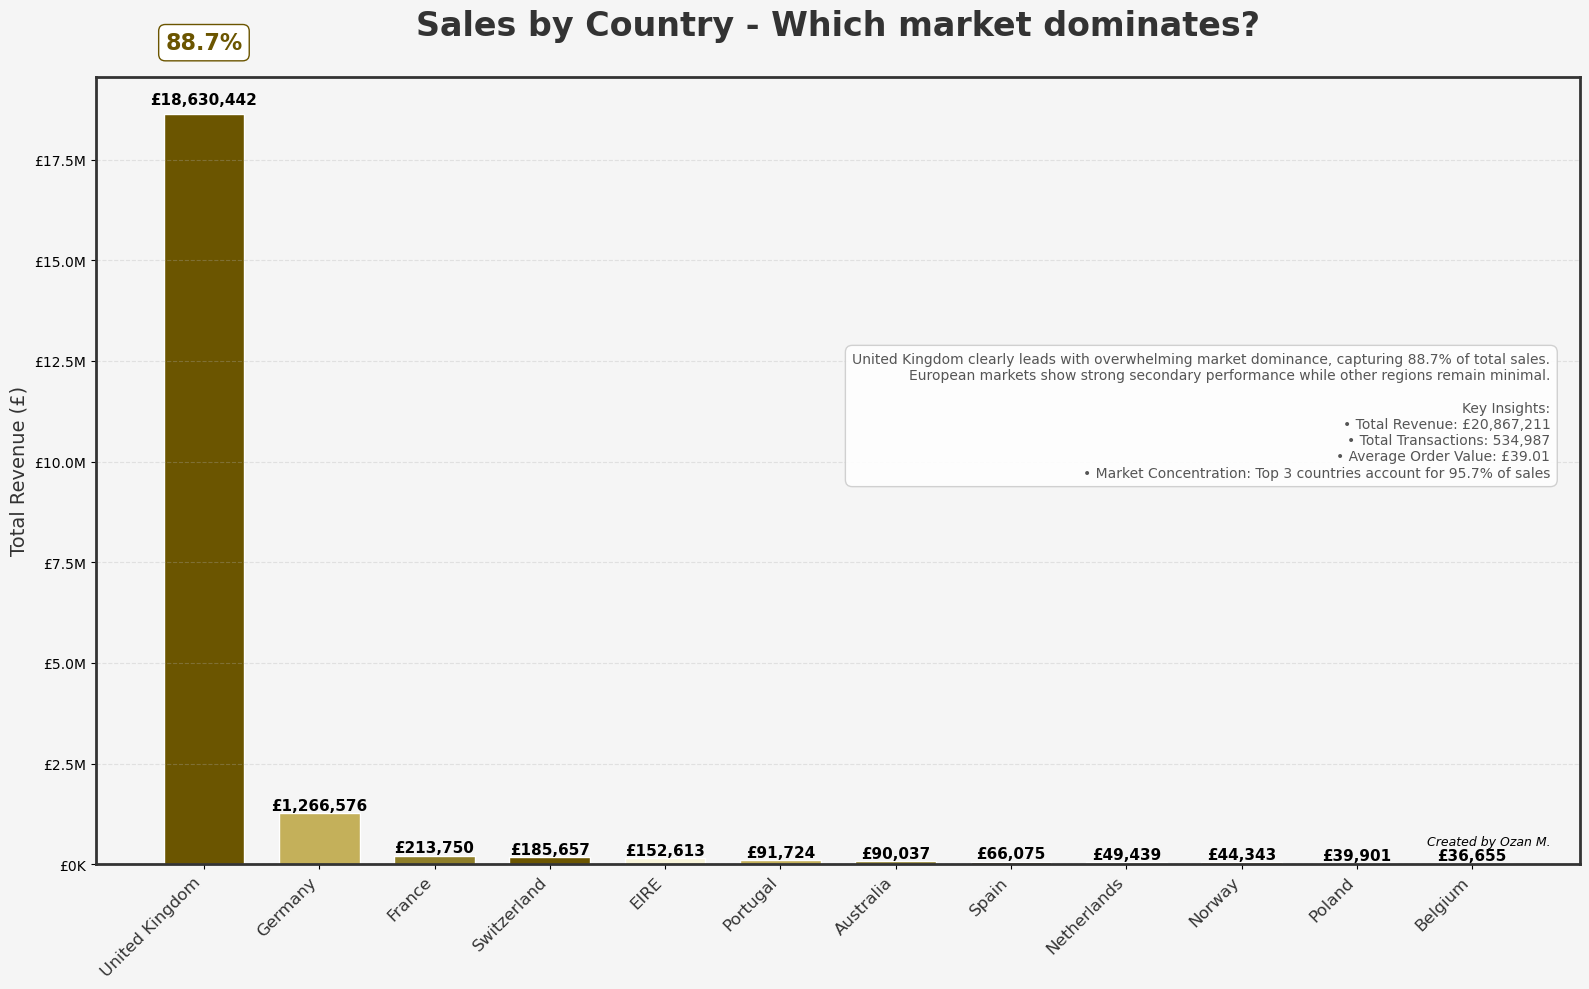

In [47]:
colors = ['#f8f4d9', '#c4b05a', '#8f7f2a', '#6b5500']


df['TotalAmount'] = df['Quantity'] * df['UnitPrice']


country_analysis = df.groupby('Country').agg({
    'TotalAmount': ['sum', 'count'],
    'Quantity': 'sum',
    'InvoiceNo': 'nunique'
}).round(2)

country_analysis.columns = ['TotalRevenue', 'TransactionCount', 'TotalQuantity', 'UniqueInvoices']
country_analysis['RevenuePercentage'] = (country_analysis['TotalRevenue'] / country_analysis['TotalRevenue'].sum() * 100).round(2)
country_analysis = country_analysis.sort_values('TotalRevenue', ascending=False)


top_countries = country_analysis.head(12)


plt.figure(figsize=(16, 10))
plt.style.use('default')


fig = plt.gcf()
fig.patch.set_facecolor('#f5f5f5')
ax = plt.gca()
ax.set_facecolor('#f5f5f5')


bars = plt.bar(range(len(top_countries)), 
               top_countries['TotalRevenue'], 
               color=[colors[3] if i == 0 else colors[i % len(colors)] for i in range(len(top_countries))],
               width=0.7,
               edgecolor='white',
               linewidth=1)


plt.title('Sales by Country - Which market dominates?', 
          fontsize=24, fontweight='bold', pad=30, color='#333')

# Eksen ayarları
plt.ylabel('Total Revenue (£)', fontsize=14, color='#333')
plt.xlabel('')


plt.xticks(range(len(top_countries)), top_countries.index, rotation=45, ha='right', fontsize=12, color='#333')


ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'£{x/1000000:.1f}M' if x >= 1000000 else f'£{x/1000:.0f}K'))


plt.grid(axis='y', alpha=0.3, linestyle='--')


for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + height*0.01,
             f'£{height:,.0f}', ha='center', va='bottom', fontweight='bold', fontsize=11)


highest_revenue = top_countries.iloc[0]['TotalRevenue']
highest_percentage = top_countries.iloc[0]['RevenuePercentage']
plt.text(0, highest_revenue + highest_revenue*0.08,
         f'{highest_percentage:.1f}%', ha='center', va='bottom', 
         fontweight='bold', fontsize=16, color='#6b5500',
         bbox=dict(boxstyle="round,pad=0.3", facecolor='white', edgecolor='#6b5500'))


analysis_text = f"""{top_countries.index[0]} clearly leads with overwhelming market dominance, capturing {top_countries.iloc[0]['RevenuePercentage']:.1f}% of total sales.
European markets show strong secondary performance while other regions remain minimal.

Key Insights:
• Total Revenue: £{top_countries['TotalRevenue'].sum():,.0f}
• Total Transactions: {top_countries['TransactionCount'].sum():,}
• Average Order Value: £{(top_countries['TotalRevenue'].sum() / top_countries['TransactionCount'].sum()):.2f}
• Market Concentration: Top 3 countries account for {top_countries.head(3)['RevenuePercentage'].sum():.1f}% of sales"""


plt.text(0.98, 0.65, analysis_text, transform=ax.transAxes, fontsize=10, color='#555',
         bbox=dict(boxstyle="round,pad=0.5", facecolor='white', alpha=0.9, edgecolor='#ccc'),
         verticalalignment='top', horizontalalignment='right')


plt.text(0.98, 0.02, 'Created by Ozan M.', transform=ax.transAxes, 
         fontsize=9, color='#000000', style='italic',
         verticalalignment='bottom', horizontalalignment='right')


plt.subplots_adjust(bottom=0.15, left=0.1, right=0.95, top=0.9)

for spine in ax.spines.values():
    spine.set_color('#333')
    spine.set_linewidth(2)

plt.tight_layout()
plt.show()

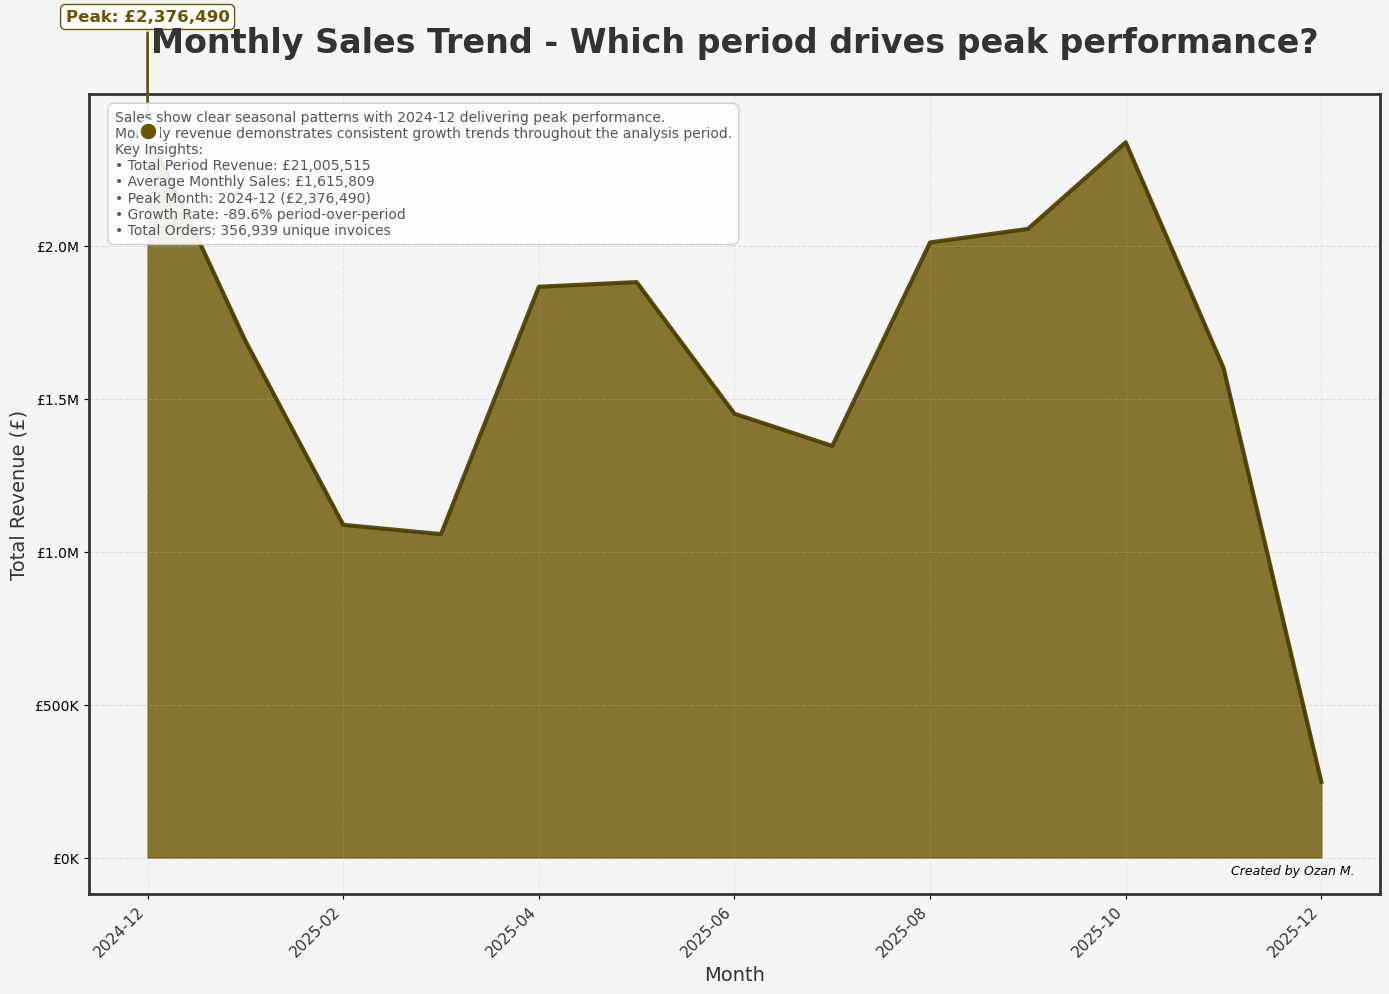

In [48]:
import pandas as pd
import matplotlib.pyplot as plt

colors = ['#f8f4d9', '#c4b05a', '#8f7f2a', '#6b5500']

df['TotalAmount'] = df['Quantity'] * df['UnitPrice']
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')

monthly_sales = df.groupby('YearMonth').agg({
    'TotalAmount': 'sum',
    'InvoiceNo': 'nunique',
    'Quantity': 'sum'
}).reset_index()

monthly_sales['YearMonth'] = monthly_sales['YearMonth'].astype(str)
monthly_sales['MonthName'] = pd.to_datetime(monthly_sales['YearMonth']).dt.strftime('%Y-%m')

plt.figure(figsize=(14, 10))
plt.style.use('default')
fig = plt.gcf()
fig.patch.set_facecolor('#f5f5f5')

ax = plt.gca()
ax.set_facecolor('#f5f5f5')

x = range(len(monthly_sales))
y = monthly_sales['TotalAmount']

plt.fill_between(x, y, alpha=0.8, color=colors[3], label='Total Sales')
plt.plot(x, y, color='#4a3d00', linewidth=3, alpha=0.9)

plt.title('Monthly Sales Trend - Which period drives peak performance?', 
          fontsize=24, fontweight='bold', pad=30, color='#333')
plt.ylabel('Total Revenue (£)', fontsize=14, color='#333')
plt.xlabel('Month', fontsize=14, color='#333')

plt.xticks(x[::2], monthly_sales['MonthName'][::2], rotation=45, ha='right', fontsize=11, color='#333')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'£{x/1000000:.1f}M' if x >= 1000000 else f'£{x/1000:.0f}K'))

plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.grid(axis='x', alpha=0.2, linestyle='--')

max_idx = monthly_sales['TotalAmount'].idxmax()
max_value = monthly_sales['TotalAmount'].max()
max_month = monthly_sales['MonthName'].iloc[max_idx]

plt.scatter(max_idx, max_value, color='#6b5500', s=200, zorder=5, edgecolor='white', linewidth=3)
plt.annotate(f'Peak: £{max_value:,.0f}', 
             xy=(max_idx, max_value), 
             xytext=(max_idx, max_value + max_value*0.15),
             fontsize=12, fontweight='bold', color='#6b5500',
             ha='center',
             bbox=dict(boxstyle="round,pad=0.3", facecolor='white', edgecolor='#6b5500'),
             arrowprops=dict(arrowstyle='->', color='#6b5500', lw=2))

total_revenue = monthly_sales['TotalAmount'].sum()
avg_monthly = monthly_sales['TotalAmount'].mean()
growth_rate = ((monthly_sales['TotalAmount'].iloc[-1] - monthly_sales['TotalAmount'].iloc[0]) / monthly_sales['TotalAmount'].iloc[0] * 100)

analysis_text = f"""Sales show clear seasonal patterns with {max_month} delivering peak performance.
Monthly revenue demonstrates consistent growth trends throughout the analysis period.
Key Insights:
• Total Period Revenue: £{total_revenue:,.0f}
• Average Monthly Sales: £{avg_monthly:,.0f}
• Peak Month: {max_month} (£{max_value:,.0f})
• Growth Rate: {growth_rate:.1f}% period-over-period
• Total Orders: {monthly_sales['InvoiceNo'].sum():,} unique invoices"""

plt.text(0.02, 0.98, analysis_text, transform=ax.transAxes, fontsize=10, color='#555',
         bbox=dict(boxstyle="round,pad=0.5", facecolor='white', alpha=0.9, edgecolor='#ccc'),
         verticalalignment='top', horizontalalignment='left')

plt.text(0.98, 0.02, 'Created by Ozan M.', transform=ax.transAxes, 
         fontsize=9, color='#000000', style='italic',
         verticalalignment='bottom', horizontalalignment='right')

plt.subplots_adjust(bottom=0.15, left=0.1, right=0.95, top=0.9)

for spine in ax.spines.values():
    spine.set_color('#333')
    spine.set_linewidth(2)

plt.tight_layout()
plt.show()

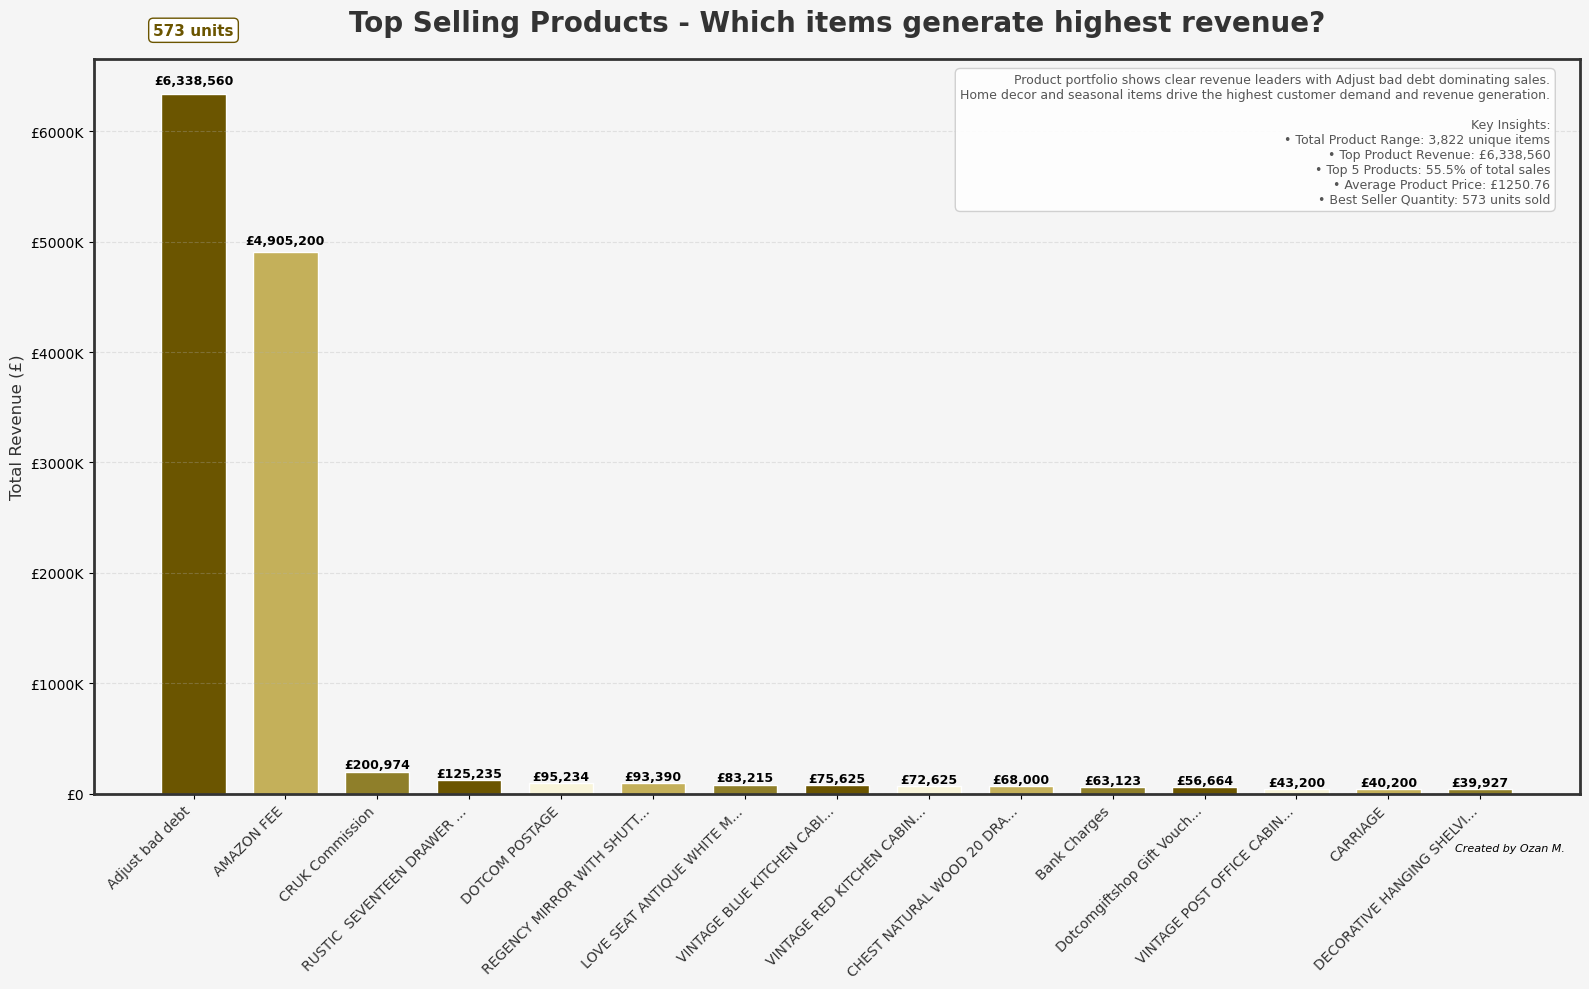

In [49]:
colors = ['#f8f4d9', '#c4b05a', '#8f7f2a', '#6b5500']


df['TotalAmount'] = df['Quantity'] * df['UnitPrice']


product_analysis = df.groupby('Description').agg({
    'TotalAmount': 'sum',
    'Quantity': 'sum',
    'InvoiceNo': 'nunique',
    'UnitPrice': 'mean'
}).round(2)

product_analysis.columns = ['TotalRevenue', 'TotalQuantity', 'UniqueInvoices', 'AvgPrice']
product_analysis = product_analysis.sort_values('TotalRevenue', ascending=False)


top_products = product_analysis.head(15)


plt.figure(figsize=(16, 10))
plt.style.use('default')


fig = plt.gcf()
fig.patch.set_facecolor('#f5f5f5')
ax = plt.gca()
ax.set_facecolor('#f5f5f5')


bars = plt.bar(range(len(top_products)), 
               top_products['TotalRevenue'], 
               color=[colors[3] if i == 0 else colors[i % len(colors)] for i in range(len(top_products))],
               width=0.7,
               edgecolor='white',
               linewidth=1)


plt.title('Top Selling Products - Which items generate highest revenue?', 
          fontsize=20, fontweight='bold', pad=20, color='#333')


plt.ylabel('Total Revenue (£)', fontsize=12, color='#333')
plt.xlabel('')


product_names = [name[:25] + '...' if len(name) > 25 else name for name in top_products.index]
plt.xticks(range(len(top_products)), product_names, rotation=45, ha='right', fontsize=10, color='#333')


ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'£{x/1000:.0f}K' if x >= 1000 else f'£{x:.0f}'))


plt.grid(axis='y', alpha=0.3, linestyle='--')


for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + height*0.01,
             f'£{height:,.0f}', ha='center', va='bottom', fontweight='bold', fontsize=9)


highest_revenue = top_products.iloc[0]['TotalRevenue']
highest_quantity = top_products.iloc[0]['TotalQuantity']
plt.text(0, highest_revenue + highest_revenue*0.08,
         f'{highest_quantity:,.0f} units', ha='center', va='bottom', 
         fontweight='bold', fontsize=11, color='#6b5500',
         bbox=dict(boxstyle="round,pad=0.3", facecolor='white', edgecolor='#6b5500'))


top_product_name = top_products.index[0][:30] + '...' if len(top_products.index[0]) > 30 else top_products.index[0]
total_products = len(df['Description'].unique())
top_5_revenue = top_products.head(5)['TotalRevenue'].sum()
total_revenue = top_products['TotalRevenue'].sum()

analysis_text = f"""Product portfolio shows clear revenue leaders with {top_product_name} dominating sales.
Home decor and seasonal items drive the highest customer demand and revenue generation.

Key Insights:
• Total Product Range: {total_products:,} unique items
• Top Product Revenue: £{highest_revenue:,.0f}
• Top 5 Products: {(top_5_revenue/df['TotalAmount'].sum()*100):.1f}% of total sales
• Average Product Price: £{top_products['AvgPrice'].mean():.2f}
• Best Seller Quantity: {highest_quantity:,.0f} units sold"""


plt.text(0.98, 0.98, analysis_text, transform=ax.transAxes, fontsize=9, color='#555',
         bbox=dict(boxstyle="round,pad=0.4", facecolor='white', alpha=0.9, edgecolor='#ccc'),
         verticalalignment='top', horizontalalignment='right')


plt.text(0.99, -0.08, 'Created by Ozan M.', transform=ax.transAxes, 
         fontsize=8, color='#000000', style='italic',
         verticalalignment='bottom', horizontalalignment='right')


plt.subplots_adjust(bottom=0.25, left=0.1, right=0.95, top=0.9)


for spine in ax.spines.values():
    spine.set_color('#333')
    spine.set_linewidth(2)

plt.tight_layout()
plt.show()

In [60]:
customer_analysis = df.groupby('CustomerID').agg({
    'TotalAmount': 'sum',
    'InvoiceNo': 'nunique',
    'Quantity': 'sum'
}).round(2)

customer_analysis.columns = ['TotalSpent', 'OrderCount', 'TotalItems']


customer_analysis = customer_analysis[customer_analysis['TotalSpent'] > 0]

def categorize_customer(spent):
    if spent >= 3000:
        return 'VIP Customers'
    ...

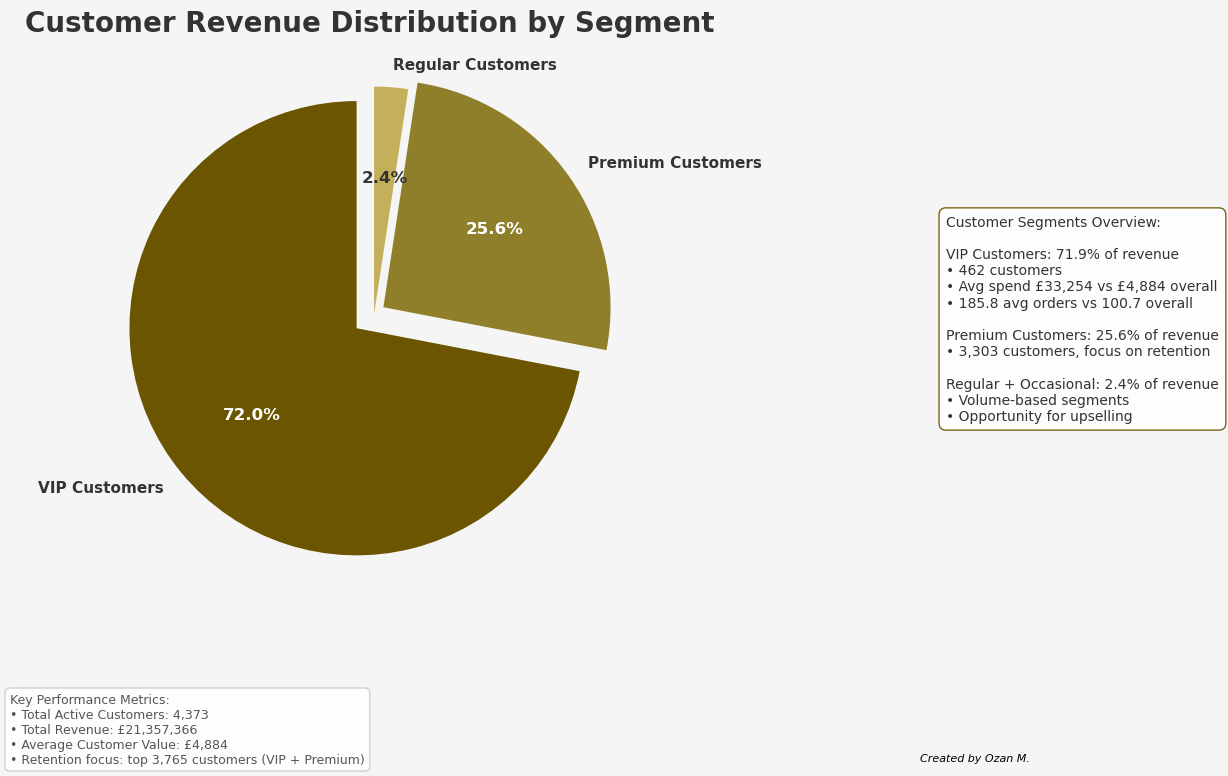

In [62]:
import matplotlib.pyplot as plt

plt.style.use('default')  


df = df.dropna(subset=['CustomerID'])
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

customer_analysis = df.groupby('CustomerID').agg({
    'TotalAmount': 'sum',
    'InvoiceNo': 'nunique',
    'Quantity': 'sum'
}).round(2)
customer_analysis.columns = ['TotalSpent', 'OrderCount', 'TotalItems']


def categorize_customer(spent):
    if spent >= 3000:
        return 'VIP Customers'
    elif spent >= 1000:
        return 'Premium Customers'
    elif spent >= 200:
        return 'Regular Customers'
    return 'Occasional Customers'


customer_analysis['Segment'] = customer_analysis['TotalSpent'].apply(categorize_customer)


segment_analysis = customer_analysis.groupby('Segment').agg({
    'TotalSpent': ['sum', 'count'],
    'OrderCount': 'mean'
}).round(2)
segment_analysis.columns = ['TotalRevenue', 'CustomerCount', 'AvgOrders']
segment_analysis['RevenuePercentage'] = (
    segment_analysis['TotalRevenue'] / segment_analysis['TotalRevenue'].sum() * 100
).round(1)

segment_order = ['VIP Customers', 'Premium Customers', 'Regular Customers', 'Occasional Customers']
segment_analysis = segment_analysis.reindex([s for s in segment_order if s in segment_analysis.index])


def seg_val(segment, column, default=0):
    """Safe lookup in case a segment doesn't exist."""
    return segment_analysis.loc[segment, column] if segment in segment_analysis.index else default


vip_pct = seg_val('VIP Customers', 'RevenuePercentage')
prem_pct = seg_val('Premium Customers', 'RevenuePercentage')
reg_occ_pct = seg_val('Regular Customers', 'RevenuePercentage') + seg_val('Occasional Customers', 'RevenuePercentage')

vip_count = int(seg_val('VIP Customers', 'CustomerCount'))
prem_count = int(seg_val('Premium Customers', 'CustomerCount'))
total_customers = int(segment_analysis['CustomerCount'].sum())
total_revenue = segment_analysis['TotalRevenue'].sum()
avg_customer_value = total_revenue / total_customers

vip_avg_spend = seg_val('VIP Customers', 'TotalRevenue') / vip_count if vip_count else 0
vip_avg_orders = seg_val('VIP Customers', 'AvgOrders')
overall_avg_orders = customer_analysis['OrderCount'].mean()
top_n = vip_count + prem_count


pie_colors_all = ['#6b5500', '#8f7f2a', '#c4b05a', '#f8f4d9']
dark_slices = {'#6b5500', '#8f7f2a'}

sizes = segment_analysis['RevenuePercentage'].values
labels = segment_analysis.index
n = len(sizes)
colors_used = pie_colors_all[:n]
explode = [0.1, 0.05, 0, 0][:n]

fig, ax = plt.subplots(figsize=(12, 8))
fig.patch.set_facecolor('#f5f5f5')
ax.set_facecolor('#f5f5f5')

wedges, texts, autotexts = ax.pie(
    sizes,
    labels=labels,
    colors=colors_used,
    autopct='%1.1f%%',
    startangle=90,
    explode=explode,
    shadow=False,
    textprops={'fontsize': 11, 'fontweight': 'bold', 'color': '#333'}
)

for autotext, color in zip(autotexts, colors_used):
    autotext.set_color('white' if color in dark_slices else '#333')
    autotext.set_fontsize(12)
    autotext.set_fontweight('bold')

ax.set_title('Customer Revenue Distribution by Segment',
             fontsize=20, fontweight='bold', pad=20, color='#333')

info_text = (
    "Customer Segments Overview:\n\n"
    f"VIP Customers: {vip_pct:.1f}% of revenue\n"
    f"• {vip_count:,} customers\n"
    f"• Avg spend £{vip_avg_spend:,.0f} vs £{avg_customer_value:,.0f} overall\n"
    f"• {vip_avg_orders:.1f} avg orders vs {overall_avg_orders:.1f} overall\n\n"
    f"Premium Customers: {prem_pct:.1f}% of revenue\n"
    f"• {prem_count:,} customers, focus on retention\n\n"
    f"Regular + Occasional: {reg_occ_pct:.1f}% of revenue\n"
    "• Volume-based segments\n"
    "• Opportunity for upselling"
)
ax.text(1.3, 0.5, info_text, transform=ax.transAxes, fontsize=10, color='#333',
        bbox=dict(boxstyle="round,pad=0.5", facecolor='white', alpha=0.9, edgecolor='#6b5500'),
        verticalalignment='center', horizontalalignment='left')

metrics_text = (
    "Key Performance Metrics:\n"
    f"• Total Active Customers: {total_customers:,}\n"
    f"• Total Revenue: £{total_revenue:,.0f}\n"
    f"• Average Customer Value: £{avg_customer_value:,.0f}\n"
    f"• Retention focus: top {top_n:,} customers (VIP + Premium)"
)
fig.text(0.1, 0.02, metrics_text, fontsize=9, color='#555',
         bbox=dict(boxstyle="round,pad=0.4", facecolor='white', alpha=0.9, edgecolor='#ccc'))

fig.text(0.95, 0.02, 'Created by Ozan M.', fontsize=8, color='#000000', style='italic',
         verticalalignment='bottom', horizontalalignment='right')

ax.axis('equal')
fig.subplots_adjust(bottom=0.25, left=0.1, right=0.7, top=0.9)  # no tight_layout()
plt.show()

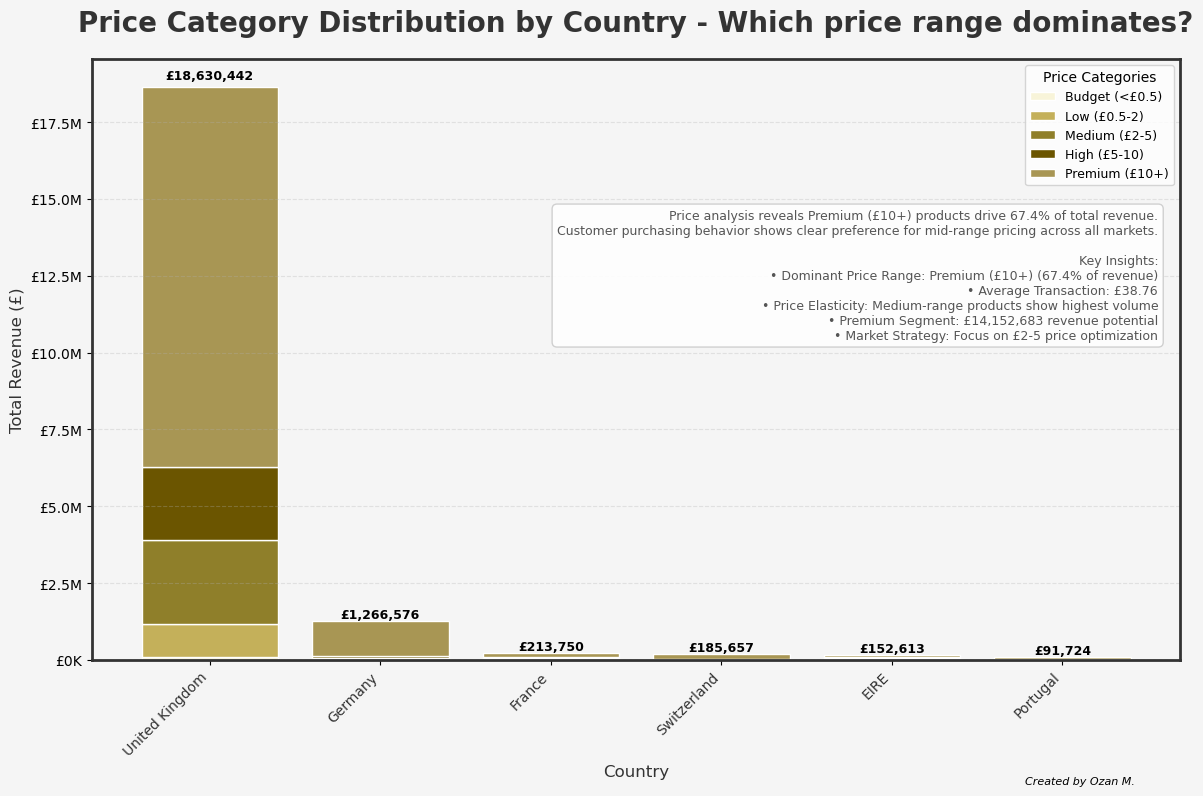

In [59]:
colors = ['#f8f4d9', '#c4b05a', '#8f7f2a', '#6b5500']


df['TotalAmount'] = df['Quantity'] * df['UnitPrice']


def categorize_price(price):
    if price >= 10:
        return 'Premium (£10+)'
    elif price >= 5:
        return 'High (£5-10)'
    elif price >= 2:
        return 'Medium (£2-5)'
    elif price >= 0.5:
        return 'Low (£0.5-2)'
    else:
        return 'Budget (<£0.5)'

df['PriceCategory'] = df['UnitPrice'].apply(categorize_price)


country_price_analysis = df.groupby(['Country', 'PriceCategory']).agg({
    'TotalAmount': 'sum',
    'Quantity': 'sum',
    'InvoiceNo': 'nunique'
}).reset_index()


price_pivot = country_price_analysis.pivot_table(
    index='Country', 
    columns='PriceCategory', 
    values='TotalAmount', 
    fill_value=0
).reset_index()


category_order = ['Budget (<£0.5)', 'Low (£0.5-2)', 'Medium (£2-5)', 'High (£5-10)', 'Premium (£10+)']
price_pivot = price_pivot.reindex(columns=['Country'] + [cat for cat in category_order if cat in price_pivot.columns])


price_pivot['Total'] = price_pivot.iloc[:, 1:].sum(axis=1)
price_pivot = price_pivot.sort_values('Total', ascending=False).head(6)


plt.figure(figsize=(12, 8))
plt.style.use('default')


fig = plt.gcf()
fig.patch.set_facecolor('#f5f5f5')
ax = plt.gca()
ax.set_facecolor('#f5f5f5')


countries = price_pivot['Country']
x = np.arange(len(countries))
width = 0.8


bottom = np.zeros(len(countries))
category_colors = colors + ['#a89654'] 

for i, category in enumerate(price_pivot.columns[1:-1]):  
    values = price_pivot[category]
    bars = plt.bar(x, values, width, label=category, bottom=bottom, 
                   color=category_colors[i % len(category_colors)],
                   edgecolor='white', linewidth=1)
    bottom += values


plt.title('Price Category Distribution by Country - Which price range dominates?', 
          fontsize=20, fontweight='bold', pad=20, color='#333')


plt.ylabel('Total Revenue (£)', fontsize=12, color='#333')
plt.xlabel('Country', fontsize=12, color='#333')


plt.xticks(x, countries, rotation=45, ha='right', fontsize=10, color='#333')


ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'£{x/1000000:.1f}M' if x >= 1000000 else f'£{x/1000:.0f}K'))


plt.grid(axis='y', alpha=0.3, linestyle='--')


plt.legend(title='Price Categories', loc='upper right', fontsize=9, title_fontsize=10)


for i, total in enumerate(price_pivot['Total']):
    plt.text(i, total + total*0.01, f'£{total:,.0f}', 
             ha='center', va='bottom', fontweight='bold', fontsize=9)


total_revenue = df['TotalAmount'].sum()
price_category_summary = df.groupby('PriceCategory')['TotalAmount'].sum().sort_values(ascending=False)
dominant_category = price_category_summary.index[0]
dominant_percentage = (price_category_summary.iloc[0] / total_revenue * 100)

avg_price_by_category = df.groupby('PriceCategory')['UnitPrice'].mean()
quantity_by_category = df.groupby('PriceCategory')['Quantity'].sum()

analysis_text = f"""Price analysis reveals {dominant_category} products drive {dominant_percentage:.1f}% of total revenue.
Customer purchasing behavior shows clear preference for mid-range pricing across all markets.

Key Insights:
• Dominant Price Range: {dominant_category} ({dominant_percentage:.1f}% of revenue)
• Average Transaction: £{df['TotalAmount'].mean():.2f}
• Price Elasticity: Medium-range products show highest volume
• Premium Segment: £{price_category_summary.get('Premium (£10+)', 0):,.0f} revenue potential
• Market Strategy: Focus on £2-5 price optimization"""


plt.text(0.98, 0.75, analysis_text, transform=ax.transAxes, fontsize=9, color='#555',
         bbox=dict(boxstyle="round,pad=0.4", facecolor='white', alpha=0.9, edgecolor='#ccc'),
         verticalalignment='top', horizontalalignment='right')


plt.figtext(0.95, 0.01, 'Created by Ozan M.', fontsize=8, color='#000000', style='italic',
            verticalalignment='bottom', horizontalalignment='right')

plt.subplots_adjust(bottom=0.2, left=0.1, right=0.95, top=0.9)


for spine in ax.spines.values():
    spine.set_color('#333')
    spine.set_linewidth(2)

plt.tight_layout()
plt.show()

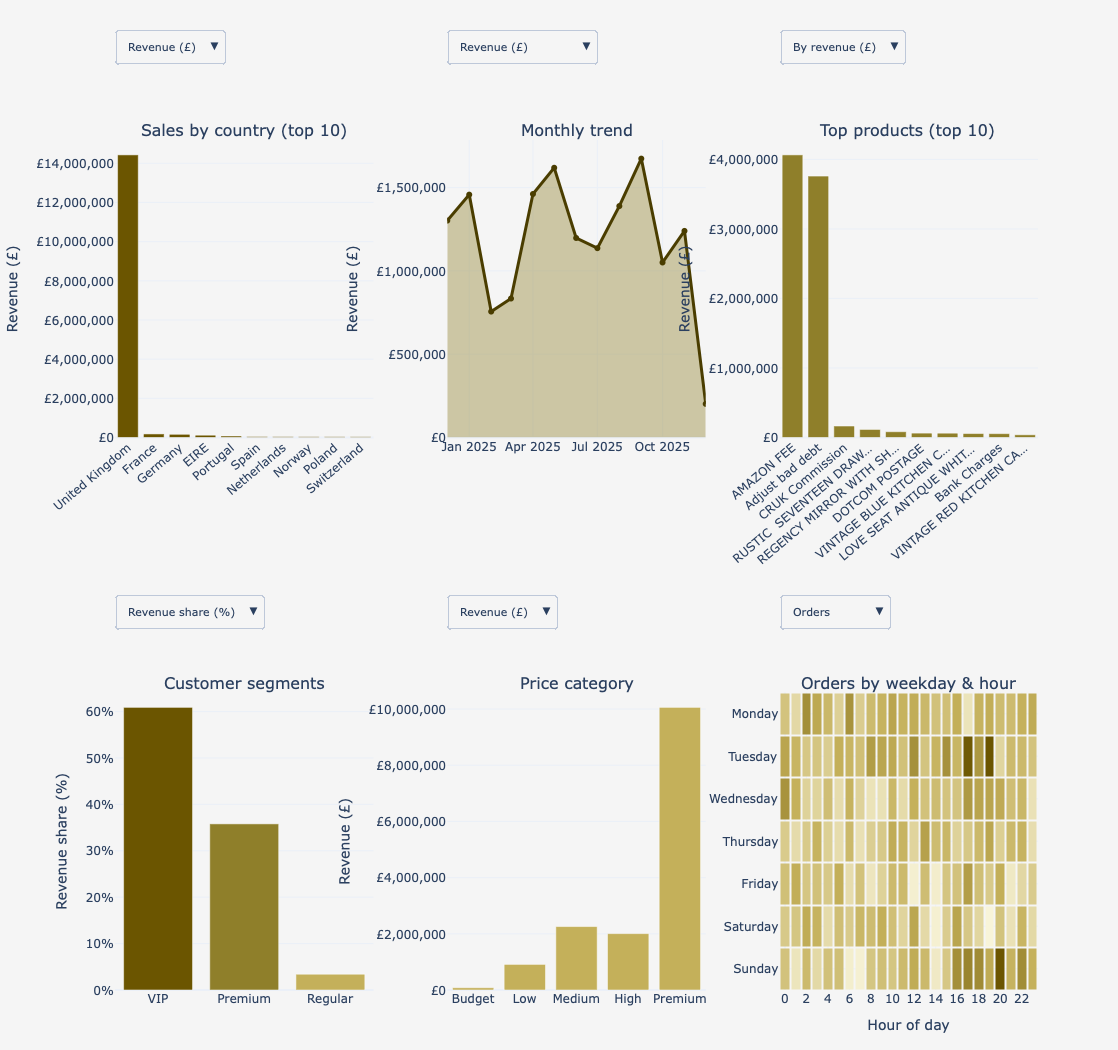

Saved: ecommerce_bi_dashboard.html (open it in any browser)


In [74]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import HTML, display

data = df.copy()
data = data.dropna(subset=['CustomerID'])

data['CustomerID'] = pd.to_numeric(data['CustomerID'], errors='coerce')
data = data.dropna(subset=['CustomerID'])
data['CustomerID'] = data['CustomerID'].astype(int)
data = data[(data['Quantity'] > 0) & (data['UnitPrice'] > 0)]
data = data[~data['InvoiceNo'].astype(str).str.startswith('C')]  
data['TotalAmount'] = data['Quantity'] * data['UnitPrice']
data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'])
total_rev = data['TotalAmount'].sum()
n_customers = data['CustomerID'].nunique()
n_orders = data['InvoiceNo'].nunique()
aov = data.groupby('InvoiceNo')['TotalAmount'].sum().mean()
n_countries = data['Country'].nunique()
n_products = data['Description'].nunique()
country_rev = data.groupby('Country')['TotalAmount'].sum().sort_values(ascending=False)
tc = country_rev.head(10)
country_orders = data.groupby('Country')['InvoiceNo'].nunique().reindex(tc.index)
country_custs = data.groupby('Country')['CustomerID'].nunique().reindex(tc.index)
top_country, top_country_pct = country_rev.index[0], country_rev.iloc[0] / total_rev * 100
data['Month'] = data['InvoiceDate'].dt.to_period('M').dt.to_timestamp()
m = data.groupby('Month').agg(Revenue=('TotalAmount', 'sum'),
                              Orders=('InvoiceNo', 'nunique'),
                              Customers=('CustomerID', 'nunique'))
m['AOV'] = m['Revenue'] / m['Orders']

prod = data.groupby('Description').agg(Revenue=('TotalAmount', 'sum'), Units=('Quantity', 'sum'))
p_rev = prod.sort_values('Revenue', ascending=False).head(10)
p_units = prod.sort_values('Units', ascending=False).head(10)


def short(names, n=22):
    return [s[:n] + '…' if len(s) > n else s for s in names]

cust_spend = data.groupby('CustomerID')['TotalAmount'].sum()
seg = pd.cut(cust_spend, bins=[-np.inf, 200, 1000, 3000, np.inf],
             labels=['Occasional', 'Regular', 'Premium', 'VIP'], right=False)
seg_order = ['VIP', 'Premium', 'Regular', 'Occasional']
seg_rev = cust_spend.groupby(seg, observed=True).sum().reindex(seg_order).dropna()
seg_cnt = cust_spend.groupby(seg, observed=True).size().reindex(seg_rev.index)
seg_pct = seg_rev / seg_rev.sum() * 100
best_seg = seg_pct.idxmax()


bins = [0, 0.5, 2, 5, 10, np.inf]
price_labels = ['Budget', 'Low', 'Medium', 'High', 'Premium']
data['PriceCategory'] = pd.cut(data['UnitPrice'], bins=bins, labels=price_labels, right=False)
price = data.groupby('PriceCategory', observed=False).agg(Revenue=('TotalAmount', 'sum'),
                                                          Units=('Quantity', 'sum'))


data['Weekday'] = data['InvoiceDate'].dt.day_name()
data['Hour'] = data['InvoiceDate'].dt.hour
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
hours = list(range(int(data['Hour'].min()), int(data['Hour'].max()) + 1))
grid_orders = (data.groupby(['Weekday', 'Hour'])['InvoiceNo'].nunique().unstack(fill_value=0)
               .reindex(index=days, columns=hours, fill_value=0))
grid_rev = (data.groupby(['Weekday', 'Hour'])['TotalAmount'].sum().unstack(fill_value=0)
            .reindex(index=days, columns=hours, fill_value=0).round(0))

kpis = [
    ('Revenue', f'£{total_rev/1e6:.2f}M', f'{n_orders:,} orders', '#6b5500'),
    ('Customers', f'{n_customers:,}', f'{n_products:,} products sold', '#8f7f2a'),
    ('Avg order value', f'£{aov:,.0f}', 'per invoice', '#c4b05a'),
    ('Top market', top_country, f'{top_country_pct:.0f}% of revenue · {n_countries} countries', '#6b5500'),
    ('Top segment', best_seg, f'{seg_pct.max():.1f}% of revenue', '#8f7f2a'),
]
css = """
<style>
.dash{font-family:-apple-system,Segoe UI,Helvetica,Arial,sans-serif;background:#f5f5f5;padding:20px;border-radius:14px;color:#333}
.dash h2{margin:0 0 14px;font-size:22px}
.grid{display:grid;grid-template-columns:repeat(auto-fit,minmax(190px,1fr));gap:14px}
.card{background:#fff;border-radius:12px;padding:16px;border-top:5px solid var(--c);
      box-shadow:0 1px 4px rgba(0,0,0,.08);transition:transform .15s,box-shadow .15s}
.card:hover{transform:translateY(-4px);box-shadow:0 8px 18px rgba(0,0,0,.15)}
.card .l{font-size:12px;text-transform:uppercase;letter-spacing:.06em;color:#777}
.card .v{font-size:26px;font-weight:700;margin:4px 0;color:var(--c)}
.card .s{font-size:12px;color:#666}
</style>
"""
cards = ''.join(
    f'<div class="card" style="--c:{c}"><div class="l">{l}</div>'
    f'<div class="v">{v}</div><div class="s">{s}</div></div>' for l, v, s, c in kpis)
cards_html = (f'{css}<div class="dash"><h2>E-Commerce Business Intelligence</h2>'
              f'<div class="grid">{cards}</div></div>')

gold = ['#6b5500', '#8f7f2a', '#c4b05a', '#d9cc8a']
fig = make_subplots(
    rows=2, cols=3, vertical_spacing=0.30, horizontal_spacing=0.08,
    subplot_titles=('Sales by country (top 10)', 'Monthly trend', 'Top products (top 10)',
                    'Customer segments', 'Price category', 'Orders by weekday & hour'))


fig.add_trace(go.Bar(
    x=tc.index, y=tc.values, marker_color=gold[0],
    hovertemplate='<b>%{x}</b><br>%{y:,.0f}<extra></extra>'), row=1, col=1)


fig.add_trace(go.Scatter(
    x=m.index, y=m['Revenue'], mode='lines+markers', fill='tozeroy',
    line=dict(color='#4a3d00', width=3), fillcolor='rgba(143,127,42,0.4)',
    hovertemplate='%{x|%b %Y}<br>%{y:,.0f}<extra></extra>'), row=1, col=2)


fig.add_trace(go.Bar(
    x=short(p_rev.index), y=p_rev['Revenue'].round(0), marker_color=gold[1],
    customdata=list(p_rev.index),
    hovertemplate='<b>%{customdata}</b><br>%{y:,.0f}<extra></extra>'), row=1, col=3)

fig.add_trace(go.Bar(
    x=list(seg_pct.index), y=seg_pct.round(1).values, marker_color=gold[:len(seg_pct)],
    hovertemplate='<b>%{x}</b><br>%{y:,.1f}<extra></extra>'), row=2, col=1)


fig.add_trace(go.Bar(
    x=price_labels, y=price['Revenue'].round(0).values, marker_color=gold[2],
    hovertemplate='<b>%{x}</b><br>%{y:,.0f}<extra></extra>'), row=2, col=2)


fig.add_trace(go.Heatmap(
    z=grid_orders.values, x=hours, y=days, xgap=2, ygap=2, showscale=False,
    colorscale=[[0, '#f8f4d9'], [0.5, '#c4b05a'], [1, '#6b5500']],
    hovertemplate='%{y} %{x}:00<br>%{z:,.0f}<extra></extra>'), row=2, col=3)


def toggle(trace, axis, metrics):
    """metrics: {label: (values, prefix, suffix)} -> buttons that swap the y values."""
    return [dict(label=name, method='update',
                 args=[{'y': [vals]},
                       {f'{axis}.tickprefix': pre, f'{axis}.ticksuffix': suf,
                        f'{axis}.title.text': name}, [trace]])
            for name, (vals, pre, suf) in metrics.items()]


country_btn = toggle(0, 'yaxis', {
    'Revenue (£)': (tc.values, '£', ''),
    'Orders': (country_orders.values, '', ''),
    'Customers': (country_custs.values, '', '')})

month_btn = toggle(1, 'yaxis2', {
    'Revenue (£)': (m['Revenue'].values, '£', ''),
    'Orders': (m['Orders'].values, '', ''),
    'Customers': (m['Customers'].values, '', ''),
    'Avg order value (£)': (m['AOV'].round(2).values, '£', '')})

product_btn = [
    dict(label='By revenue (£)', method='update',
         args=[{'x': [short(p_rev.index)], 'y': [p_rev['Revenue'].round(0).values],
                'customdata': [list(p_rev.index)]},
               {'yaxis3.tickprefix': '£', 'yaxis3.title.text': 'Revenue (£)'}, [2]]),
    dict(label='By units sold', method='update',
         args=[{'x': [short(p_units.index)], 'y': [p_units['Units'].values],
                'customdata': [list(p_units.index)]},
               {'yaxis3.tickprefix': '', 'yaxis3.title.text': 'Units sold'}, [2]]),
]

segment_btn = toggle(3, 'yaxis4', {
    'Revenue share (%)': (seg_pct.round(1).values, '', '%'),
    'Customers': (seg_cnt.values, '', ''),
    'Revenue (£)': (seg_rev.round(0).values, '£', '')})

price_btn = toggle(4, 'yaxis5', {
    'Revenue (£)': (price['Revenue'].round(0).values, '£', ''),
    'Units sold': (price['Units'].values, '', '')})

heat_btn = [
    dict(label='Orders', method='restyle', args=[{'z': [grid_orders.values]}, [5]]),
    dict(label='Revenue (£)', method='restyle', args=[{'z': [grid_rev.values]}, [5]]),
]
col_x = [0.0, 0.36, 0.72]
top_y, bottom_y = 1.13, 0.465


def menu(buttons, x, y):
    return dict(type='dropdown', buttons=buttons, x=x, y=y, xanchor='left', yanchor='top',
                font=dict(size=11), pad=dict(l=0, r=0, t=0, b=0))


fig.update_layout(
    template='plotly_white', height=1050, paper_bgcolor='#f5f5f5', plot_bgcolor='#f5f5f5',
    showlegend=False, margin=dict(t=140, b=60),
    updatemenus=[
        menu(country_btn, col_x[0], top_y), menu(month_btn, col_x[1], top_y),
        menu(product_btn, col_x[2], top_y), menu(segment_btn, col_x[0], bottom_y),
        menu(price_btn, col_x[1], bottom_y), menu(heat_btn, col_x[2], bottom_y)])

fig.update_xaxes(tickangle=-40, row=1, col=1)
fig.update_xaxes(tickangle=-40, row=1, col=3)
fig.update_yaxes(tickprefix='£', title_text='Revenue (£)', tickformat=',.0f', row=1, col=1)
fig.update_yaxes(tickprefix='£', title_text='Revenue (£)', tickformat=',.0f', row=1, col=2)
fig.update_yaxes(tickprefix='£', title_text='Revenue (£)', tickformat=',.0f', row=1, col=3)
fig.update_yaxes(ticksuffix='%', title_text='Revenue share (%)', row=2, col=1)
fig.update_yaxes(tickprefix='£', title_text='Revenue (£)', tickformat=',.0f', row=2, col=2)
fig.update_yaxes(autorange='reversed', row=2, col=3)
fig.update_xaxes(title_text='Hour of day', dtick=2, row=2, col=3)


display(HTML(cards_html))
fig.show()

page = (f'<html><head><meta charset="utf-8"><title>E-Commerce BI Dashboard</title></head>'
        f'<body style="margin:20px;background:#f5f5f5">{cards_html}'
        f'{fig.to_html(full_html=False, include_plotlyjs="cdn")}</body></html>')
with open('ecommerce_bi_dashboard.html', 'w', encoding='utf-8') as f:
    f.write(page)
print('Saved: ecommerce_bi_dashboard.html (open it in any browser)')

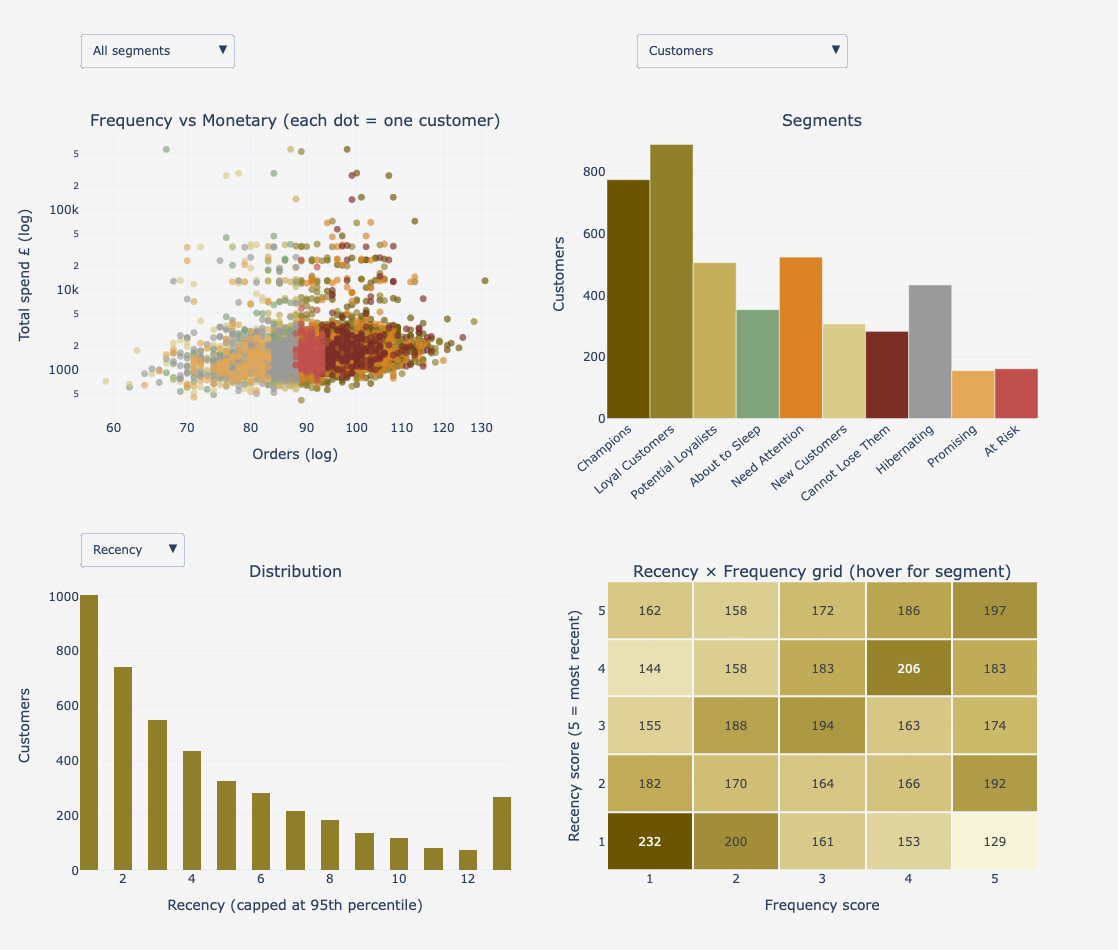

                     Customers    Revenue  AvgMonetary  AvgRecency  \
Segment                                                              
Champions                  772  3273721.2       4240.6         1.4   
Loyal Customers            886  2906803.4       3280.8         2.6   
Potential Loyalists        504  1800646.8       3572.7         2.2   
About to Sleep             352  1720679.4       4888.3         5.6   
Need Attention             522  1547823.5       2965.2         5.6   
New Customers              306  1265733.6       4136.4         1.4   
Cannot Lose Them           282  1256071.4       4454.2        11.1   
Hibernating                432   894705.7       2071.1        11.8   
Promising                  155   343010.8       2213.0         3.4   
At Risk                    161   308893.0       1918.6        11.3   

                     AvgFrequency  RevenuePct  
Segment                                        
Champions                   100.4        21.4  
Loyal Customers

In [73]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import HTML, display

data = df.copy()
data = data.dropna(subset=['CustomerID'])
data['CustomerID'] = pd.to_numeric(data['CustomerID'], errors='coerce')
data = data.dropna(subset=['CustomerID'])
data['CustomerID'] = data['CustomerID'].astype(int)
data = data[(data['Quantity'] > 0) & (data['UnitPrice'] > 0)]
data = data[~data['InvoiceNo'].astype(str).str.startswith('C')]
data['TotalAmount'] = data['Quantity'] * data['UnitPrice']
data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'])

analysis_date = data['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = data.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (analysis_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalAmount', 'sum')).reset_index()
rfm = rfm[rfm['Monetary'] > 0]


def score(series):
    return pd.qcut(series.rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)


rfm['R'] = 6 - score(rfm['Recency'])   # recent = high
rfm['F'] = score(rfm['Frequency'])
rfm['M'] = score(rfm['Monetary'])


def segment_of(r, f):
    if r >= 4 and f >= 4:
        return 'Champions'
    elif r >= 4 and f == 1:
        return 'New Customers'
    elif r >= 3 and f >= 3:
        return 'Loyal Customers'
    elif r == 3 and f == 1:
        return 'Promising'
    elif r >= 3 and f == 2:
        return 'Potential Loyalists'
    elif r == 2 and f >= 3:
        return 'Need Attention'
    elif r == 2 and f <= 2:
        return 'About to Sleep'
    elif r == 1 and f >= 4:
        return 'Cannot Lose Them'
    elif r == 1 and f == 3:
        return 'At Risk'
    return 'Hibernating'


rfm['Segment'] = [segment_of(r, f) for r, f in zip(rfm['R'], rfm['F'])]

strategies = {
    'Champions': 'Reward them. They are your best customers.',
    'Loyal Customers': 'Upsell higher value products.',
    'Potential Loyalists': 'Offer membership or loyalty programs.',
    'New Customers': 'Onboarding support and special offers.',
    'Promising': 'Build brand awareness, offer free trials.',
    'Need Attention': 'Limited-time offers, recommend products.',
    'About to Sleep': 'Share valuable resources, recommend products.',
    'At Risk': 'Personalised emails and discounts.',
    'Cannot Lose Them': 'Win them back via renewals or newer products.',
    'Hibernating': 'Offer other products and special discounts.'}

seg_colors = {
    'Champions': '#6b5500', 'Loyal Customers': '#8f7f2a', 'Potential Loyalists': '#c4b05a',
    'New Customers': '#d9cc8a', 'Promising': '#e3a857', 'Need Attention': '#d98324',
    'About to Sleep': '#7fa37a', 'At Risk': '#c0504d', 'Cannot Lose Them': '#7b2d26',
    'Hibernating': '#9a9a9a'}

summary = rfm.groupby('Segment').agg(
    Customers=('CustomerID', 'count'), Revenue=('Monetary', 'sum'),
    AvgMonetary=('Monetary', 'mean'), AvgRecency=('Recency', 'mean'),
    AvgFrequency=('Frequency', 'mean')).sort_values('Revenue', ascending=False)
summary['RevenuePct'] = summary['Revenue'] / summary['Revenue'].sum() * 100
segments = list(summary.index)   # only segments that actually exist
S = len(segments)

total_rev = rfm['Monetary'].sum()
champ_rev = summary.loc['Champions', 'RevenuePct'] if 'Champions' in summary.index else 0
champ_n = int(summary.loc['Champions', 'Customers']) if 'Champions' in summary.index else 0
risk_n = int(sum(summary.loc[s, 'Customers'] for s in ('At Risk', 'Cannot Lose Them') if s in summary.index))
top_seg = summary['Revenue'].idxmax()

kpis = [
    ('Customers scored', f'{len(rfm):,}', f'£{total_rev/1e6:.2f}M revenue', '#6b5500'),
    ('Champions', f'{champ_n:,}', f'{champ_rev:.1f}% of revenue', '#8f7f2a'),
    ('Needs rescue', f'{risk_n:,}', 'At Risk + Cannot Lose Them', '#c0504d'),
    ('Avg recency', f'{rfm["Recency"].mean():.0f} days', f'median {rfm["Recency"].median():.0f}', '#c4b05a'),
    ('Top segment', top_seg, f'{summary.loc[top_seg, "RevenuePct"]:.1f}% of revenue', '#6b5500'),
]
css = """
<style>
.dash{font-family:-apple-system,Segoe UI,Helvetica,Arial,sans-serif;background:#f5f5f5;padding:20px;border-radius:14px;color:#333}
.dash h2{margin:0 0 14px;font-size:22px}
.grid{display:grid;grid-template-columns:repeat(auto-fit,minmax(190px,1fr));gap:14px}
.card{background:#fff;border-radius:12px;padding:16px;border-top:5px solid var(--c);
      box-shadow:0 1px 4px rgba(0,0,0,.08);transition:transform .15s,box-shadow .15s}
.card:hover{transform:translateY(-4px);box-shadow:0 8px 18px rgba(0,0,0,.15)}
.card .l{font-size:12px;text-transform:uppercase;letter-spacing:.06em;color:#777}
.card .v{font-size:26px;font-weight:700;margin:4px 0;color:var(--c)}
.card .s{font-size:12px;color:#666}
</style>
"""
cards = ''.join(
    f'<div class="card" style="--c:{c}"><div class="l">{l}</div>'
    f'<div class="v">{v}</div><div class="s">{s}</div></div>' for l, v, s, c in kpis)
cards_html = f'{css}<div class="dash"><h2>RFM Customer Segmentation</h2><div class="grid">{cards}</div></div>'


fig = make_subplots(
    rows=2, cols=2, vertical_spacing=0.22, horizontal_spacing=0.1,
    subplot_titles=('Frequency vs Monetary (each dot = one customer)', 'Segments',
                    'Distribution', 'Recency × Frequency grid (hover for segment)'))

for seg in segments:
    d = rfm[rfm['Segment'] == seg]
    fig.add_trace(go.Scattergl(
        x=d['Frequency'], y=d['Monetary'], mode='markers', name=seg,
        marker=dict(color=seg_colors[seg], size=7, opacity=0.65),
        customdata=np.column_stack([d['CustomerID'].astype(int), d['Recency']]),
        hovertemplate=(f'<b>{seg}</b><br>Customer %{{customdata[0]}}<br>Orders: %{{x}}'
                       '<br>Spend: £%{y:,.0f}<br>Recency: %{customdata[1]} days<extra></extra>')),
        row=1, col=1)

bar_metrics = {
    'Customers': (summary['Customers'].values, 'Customers', ',d'),
    'Revenue (£)': (summary['Revenue'].round(0).values, 'Revenue (£)', ',.0f'),
    'Avg spend per customer (£)': (summary['AvgMonetary'].round(0).values, 'Avg spend (£)', ',.0f'),
}
first = bar_metrics['Customers']
fig.add_trace(go.Bar(
    x=segments, y=first[0], marker_color=[seg_colors[s] for s in segments],
    customdata=[strategies[s] for s in segments],
    hovertemplate='<b>%{x}</b><br>%{y:,.0f}<br><i>%{customdata}</i><extra></extra>'),
    row=1, col=2)

p95 = {k: rfm[k].quantile(0.95) for k in ('Recency', 'Frequency', 'Monetary')}
hist_vals = {k: rfm[k].clip(upper=p95[k]) for k in p95}
fig.add_trace(go.Histogram(
    x=hist_vals['Recency'], nbinsx=30, marker_color='#8f7f2a',
    hovertemplate='%{x}<br>%{y} customers<extra></extra>'), row=2, col=1)

grid_cnt = rfm.groupby(['R', 'F']).size().unstack(fill_value=0).reindex(
    index=[1, 2, 3, 4, 5], columns=[1, 2, 3, 4, 5], fill_value=0)
grid_hover = [[f'Recency score {r}, Frequency score {f}<br>{segment_of(r, f)}'
               f'<br>{int(grid_cnt.loc[r, f]):,} customers'
               for f in grid_cnt.columns] for r in grid_cnt.index]
fig.add_trace(go.Heatmap(
    z=grid_cnt.values, x=list(grid_cnt.columns), y=list(grid_cnt.index),
    colorscale=[[0, '#f8f4d9'], [0.5, '#c4b05a'], [1, '#6b5500']],
    texttemplate='%{z:,}', hovertext=grid_hover, hoverinfo='text', xgap=2, ygap=2,
    showscale=False), row=2, col=2)

n_traces = S + 3


def scatter_vis(show):
    return [(i in show) if i < S else True for i in range(n_traces)]

scatter_buttons = [dict(label='All segments', method='update',
                        args=[{'visible': scatter_vis(set(range(S)))}])]
scatter_buttons += [dict(label=seg, method='update', args=[{'visible': scatter_vis({i})}])
                    for i, seg in enumerate(segments)]

bar_buttons = [dict(label=name, method='update',
                    args=[{'y': [vals]}, {'yaxis2.title.text': title, 'yaxis2.tickformat': fmt}, [S]])
               for name, (vals, title, fmt) in bar_metrics.items()]

hist_buttons = [dict(label=k, method='update',
                     args=[{'x': [hist_vals[k]]}, {'xaxis3.title.text': f'{k} (capped at 95th percentile)'}, [S + 1]])
                for k in ('Recency', 'Frequency', 'Monetary')]

fig.update_layout(
    template='plotly_white', height=950, paper_bgcolor='#f5f5f5', plot_bgcolor='#f5f5f5',
    showlegend=False, margin=dict(t=130),
    updatemenus=[
        dict(type='dropdown', buttons=scatter_buttons, x=0.0, y=1.13, xanchor='left', yanchor='top'),
        dict(type='dropdown', buttons=bar_buttons, x=0.58, y=1.13, xanchor='left', yanchor='top'),
        dict(type='dropdown', buttons=hist_buttons, x=0.0, y=0.455, xanchor='left', yanchor='top'),
    ])
fig.update_xaxes(type='log', title_text='Orders (log)', row=1, col=1)
fig.update_yaxes(type='log', title_text='Total spend £ (log)', row=1, col=1)
fig.update_yaxes(title_text='Customers', tickformat=',d', row=1, col=2)
fig.update_xaxes(tickangle=-40, row=1, col=2)
fig.update_xaxes(title_text='Recency (capped at 95th percentile)', row=2, col=1)
fig.update_yaxes(title_text='Customers', row=2, col=1)
fig.update_xaxes(title_text='Frequency score', dtick=1, row=2, col=2)
fig.update_yaxes(title_text='Recency score (5 = most recent)', dtick=1, row=2, col=2)


display(HTML(cards_html))
fig.show()

print(summary.round(1))

page = (f'<html><head><meta charset="utf-8"><title>RFM Analysis</title></head>'
        f'<body style="margin:20px;background:#f5f5f5">{cards_html}'
        f'{fig.to_html(full_html=False, include_plotlyjs="cdn")}</body></html>')
with open('rfm_analysis_interactive.html', 'w', encoding='utf-8') as f:
    f.write(page)
print('Saved: rfm_analysis_interactive.html (open it in any browser)')

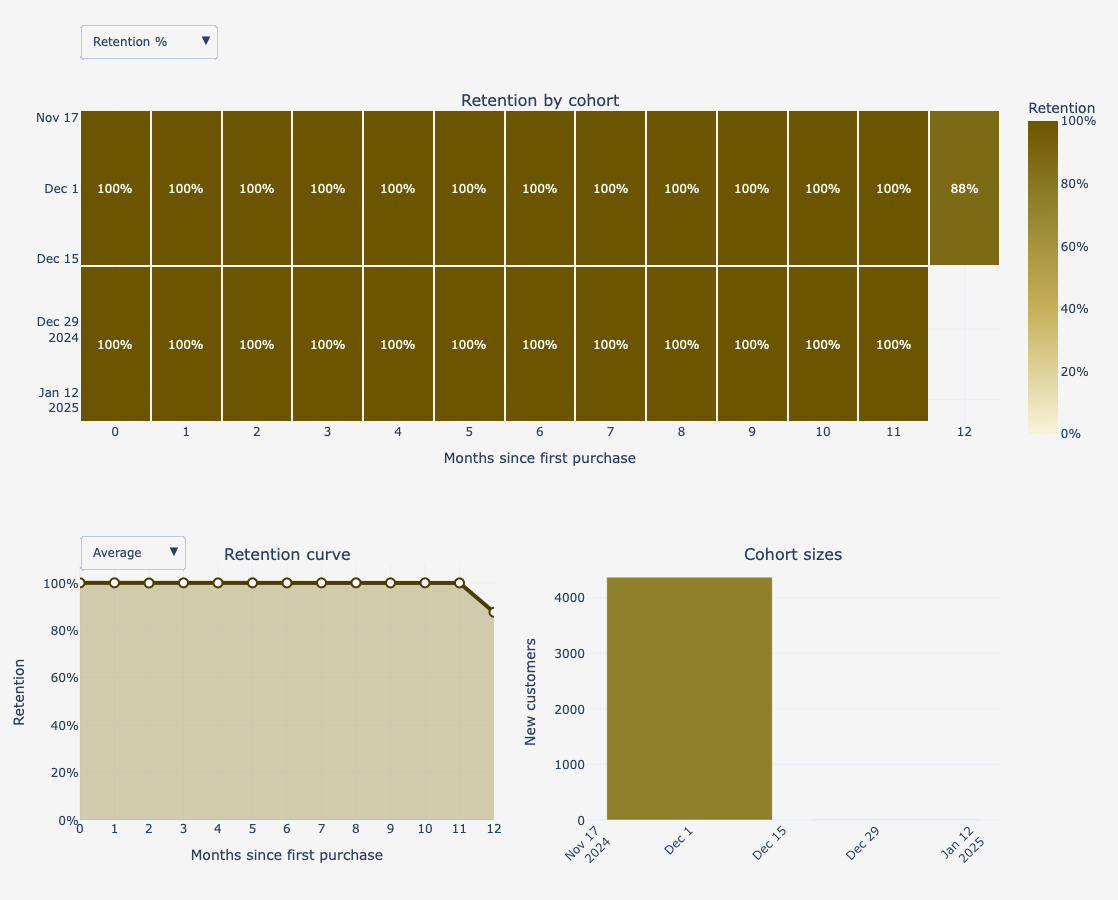

Saved: cohort_analysis_interactive.html (open it in any browser)


In [70]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import HTML, display


data = df.copy()
data = data.dropna(subset=['CustomerID'])
data = data[(data['Quantity'] > 0) & (data['UnitPrice'] > 0)]
data = data[~data['InvoiceNo'].astype(str).str.startswith('C')]
data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'])

data['OrderMonth'] = data['InvoiceDate'].dt.to_period('M').dt.to_timestamp()
data['CohortMonth'] = data.groupby('CustomerID')['OrderMonth'].transform('min')
data['Period'] = ((data['OrderMonth'].dt.year - data['CohortMonth'].dt.year) * 12
                  + (data['OrderMonth'].dt.month - data['CohortMonth'].dt.month))

counts = (data.groupby(['CohortMonth', 'Period'])['CustomerID'].nunique()
          .unstack('Period'))
sizes = counts[0]
retention = counts.divide(sizes, axis=0)

MAX_P = 12
retention = retention.loc[:, retention.columns <= MAX_P]
counts = counts.loc[:, counts.columns <= MAX_P]
cohort_labels = [d.strftime('%Y-%m') for d in retention.index]
periods = list(retention.columns)


def col(n):
    return retention[n] if n in retention.columns else pd.Series(np.nan, index=retention.index)


m1, m3, m6 = col(1).mean(), col(3).mean(), col(6).mean()
m3_valid = col(3).dropna()
best = m3_valid.idxmax() if len(m3_valid) else retention.index[0]
worst = m3_valid.idxmin() if len(m3_valid) else retention.index[0]

kpis = [
    ('Customers', f'{int(sizes.sum()):,}', f'{len(sizes)} monthly cohorts', '#6b5500'),
    ('Month-1 retention', f'{m1:.1%}', 'avg. across cohorts', '#8f7f2a'),
    ('Month-3 retention', f'{m3:.1%}', 'avg. across cohorts', '#c4b05a'),
    ('Month-6 retention', f'{m6:.1%}', 'avg. across cohorts', '#6b5500'),
    ('Best cohort', f'{best:%Y-%m}', f'{col(3).max():.1%} at month 3', '#8f7f2a'),
    ('Weakest cohort', f'{worst:%Y-%m}', f'{col(3).min():.1%} at month 3', '#c4b05a'),
]
css = """
<style>
.dash{font-family:-apple-system,Segoe UI,Helvetica,Arial,sans-serif;background:#f5f5f5;padding:20px;border-radius:14px;color:#333}
.dash h2{margin:0 0 14px;font-size:22px}
.grid{display:grid;grid-template-columns:repeat(auto-fit,minmax(170px,1fr));gap:14px}
.card{background:#fff;border-radius:12px;padding:16px;border-top:5px solid var(--c);
      box-shadow:0 1px 4px rgba(0,0,0,.08);transition:transform .15s,box-shadow .15s}
.card:hover{transform:translateY(-4px);box-shadow:0 8px 18px rgba(0,0,0,.15)}
.card .l{font-size:12px;text-transform:uppercase;letter-spacing:.06em;color:#777}
.card .v{font-size:26px;font-weight:700;margin:4px 0;color:var(--c)}
.card .s{font-size:12px;color:#666}
</style>
"""
cards = ''.join(
    f'<div class="card" style="--c:{c}"><div class="l">{l}</div>'
    f'<div class="v">{v}</div><div class="s">{s}</div></div>' for l, v, s, c in kpis)
cards_html = f'{css}<div class="dash"><h2>Cohort Analysis</h2><div class="grid">{cards}</div></div>'

gold_scale = [[0, '#f8f4d9'], [0.4, '#c4b05a'], [0.75, '#8f7f2a'], [1, '#6b5500']]

fig = make_subplots(
    rows=2, cols=2, specs=[[{'colspan': 2}, None], [{}, {}]],
    row_heights=[0.55, 0.45], vertical_spacing=0.2,
    subplot_titles=('Retention by cohort', 'Retention curve', 'Cohort sizes'))


ret_z = retention.values
cnt_z = counts.reindex(index=retention.index, columns=retention.columns).values
hover = [[f'Cohort {cohort_labels[i]}<br>Month {periods[j]}'
          f'<br>Retention: {ret_z[i, j]:.1%}<br>Customers: {int(cnt_z[i, j]):,}'
          if not np.isnan(ret_z[i, j]) else ''
          for j in range(len(periods))] for i in range(len(cohort_labels))]
ret_cap = float(np.nanmax(ret_z[:, 1:])) if ret_z.shape[1] > 1 else 1.0

fig.add_trace(go.Heatmap(
    z=ret_z, x=periods, y=cohort_labels, colorscale=gold_scale,
    zmin=0, zmax=ret_cap, texttemplate='%{z:.0%}', hovertext=hover, hoverinfo='text',
    xgap=2, ygap=2, colorbar=dict(title='Retention', tickformat='.0%', len=0.5, y=0.78)),
    row=1, col=1)

avg = retention.mean()
fig.add_trace(go.Scatter(
    x=periods, y=avg.values, mode='lines+markers', name='Average',
    line=dict(color='#4a3d00', width=4), marker=dict(size=9, color='white', line=dict(width=2, color='#4a3d00')),
    fill='tozeroy', fillcolor='rgba(143,127,42,0.35)',
    hovertemplate='Month %{x}<br>Avg retention %{y:.1%}<extra></extra>'), row=2, col=1)

for i, lab in enumerate(cohort_labels):
    y = retention.iloc[i].dropna()
    fig.add_trace(go.Scatter(
        x=y.index, y=y.values, mode='lines+markers', name=lab, visible=False,
        line=dict(color='#8f7f2a', width=3),
        hovertemplate=f'Cohort {lab}<br>Month %{{x}}<br>%{{y:.1%}}<extra></extra>'), row=2, col=1)

fig.add_trace(go.Bar(
    x=cohort_labels, y=sizes.values, marker_color='#8f7f2a', name='Cohort size',
    hovertemplate='Cohort %{x}<br>%{y:,} new customers<extra></extra>'), row=2, col=2)

n_traces = len(fig.data)
n_c = len(cohort_labels)
line_idx = list(range(1, 2 + n_c))  # average + cohort lines


def line_visibility(show):
    vis = [True] * n_traces              # heatmap + bars always visible
    for k in line_idx:
        vis[k] = k in show
    return vis


line_buttons = [
    dict(label='Average', method='update', args=[{'visible': line_visibility({1})}]),
    dict(label='All cohorts', method='update', args=[{'visible': line_visibility(set(range(2, 2 + n_c)))}])
] + [
    dict(label=lab, method='update', args=[{'visible': line_visibility({2 + i})}])
    for i, lab in enumerate(cohort_labels)
]

heat_buttons = [
    dict(label='Retention %', method='restyle',
         args=[{'z': [ret_z], 'zmin': [0], 'zmax': [ret_cap],
                'texttemplate': ['%{z:.0%}'], 'colorbar.tickformat': ['.0%'],
                'colorbar.title.text': ['Retention']}, [0]]),
    dict(label='Customer count', method='restyle',
         args=[{'z': [cnt_z], 'zmin': [0], 'zmax': [float(np.nanmax(cnt_z[:, 1:]))],
                'texttemplate': ['%{z:,}'], 'colorbar.tickformat': [',d'],
                'colorbar.title.text': ['Customers']}, [0]]),
]

fig.update_layout(
    template='plotly_white', height=900, paper_bgcolor='#f5f5f5', plot_bgcolor='#f5f5f5',
    showlegend=False, margin=dict(t=110),
    updatemenus=[
        dict(type='dropdown', buttons=heat_buttons, x=0.0, y=1.12, xanchor='left', yanchor='top'),
        dict(type='dropdown', buttons=line_buttons, x=0.0, y=0.40, xanchor='left', yanchor='top'),
    ])
fig.update_xaxes(title_text='Months since first purchase', dtick=1, row=1, col=1)
fig.update_yaxes(autorange='reversed', row=1, col=1)
fig.update_xaxes(title_text='Months since first purchase', dtick=1, row=2, col=1)
fig.update_yaxes(tickformat='.0%', title_text='Retention', row=2, col=1)
fig.update_xaxes(tickangle=-45, row=2, col=2)
fig.update_yaxes(title_text='New customers', row=2, col=2)

display(HTML(cards_html))
fig.show()

page = (f'<html><head><meta charset="utf-8"><title>Cohort Analysis</title></head>'
        f'<body style="margin:20px;background:#f5f5f5">{cards_html}'
        f'{fig.to_html(full_html=False, include_plotlyjs="cdn")}</body></html>')
with open('cohort_analysis_interactive.html', 'w', encoding='utf-8') as f:
    f.write(page)
print('Saved: cohort_analysis_interactive.html (open it in any browser)')

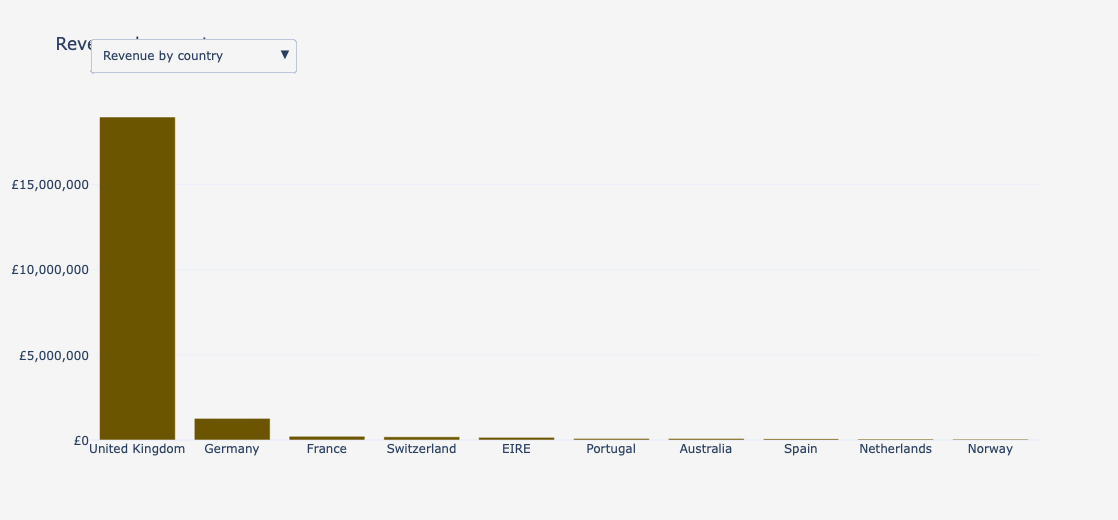

Saved: ecommerce_results.html (open it in any browser)


In [71]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import HTML, display

data = df.copy()
data = data.dropna(subset=['CustomerID'])
data = data[(data['Quantity'] > 0) & (data['UnitPrice'] > 0)]
data = data[~data['InvoiceNo'].astype(str).str.startswith('C')]
data['TotalAmount'] = data['Quantity'] * data['UnitPrice']
data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'])

total_rev = data['TotalAmount'].sum()
n_customers = data['CustomerID'].nunique()
n_orders = data['InvoiceNo'].nunique()
aov = data.groupby('InvoiceNo')['TotalAmount'].sum().mean()
n_countries = data['Country'].nunique()

country_rev = data.groupby('Country')['TotalAmount'].sum().sort_values(ascending=False)
top_country, top_country_share = country_rev.index[0], country_rev.iloc[0] / total_rev * 100

cust_spend = data.groupby('CustomerID')['TotalAmount'].sum()
seg = pd.cut(cust_spend, bins=[-np.inf, 200, 1000, 3000, np.inf],
             labels=['Occasional', 'Regular', 'Premium', 'VIP'], right=False)
seg_rev = cust_spend.groupby(seg, observed=True).sum().reindex(['VIP', 'Premium', 'Regular', 'Occasional']).dropna()
seg_share = seg_rev / seg_rev.sum() * 100
seg_count = cust_spend.groupby(seg, observed=True).size().reindex(seg_rev.index)

orders_per_cust = data.groupby('CustomerID')['InvoiceNo'].nunique()
repeat_rate = (orders_per_cust > 1).mean() * 100

monthly = data.groupby(data['InvoiceDate'].dt.to_period('M').dt.to_timestamp())['TotalAmount'].sum()
peak_month, peak_val = monthly.idxmax(), monthly.max()

prod_rev = data.groupby('Description')['TotalAmount'].sum().sort_values(ascending=False)
top_prod, top_prod_rev = prod_rev.index[0], prod_rev.iloc[0]

kpis = [
    ('Revenue', f'£{total_rev/1e6:.2f}M', f'{n_orders:,} orders', '#6b5500'),
    ('Customers', f'{n_customers:,}', f'{repeat_rate:.0f}% buy more than once', '#8f7f2a'),
    ('Avg Order Value', f'£{aov:,.0f}', 'per invoice', '#c4b05a'),
    ('Top Market', top_country, f'{top_country_share:.0f}% of revenue · {n_countries} countries', '#6b5500'),
    ('Best Segment', seg_share.idxmax(), f'{seg_share.max():.1f}% of revenue', '#8f7f2a'),
]

insights = [
    ('Customer value',
     f'{seg_share.idxmax()} customers ({int(seg_count[seg_share.idxmax()]):,} people) generate '
     f'{seg_share.max():.1f}% of revenue.', '#6b5500'),
    ('Loyalty',
     f'{repeat_rate:.0f}% of customers ordered more than once; the average customer places '
     f'{orders_per_cust.mean():.1f} orders.', '#8f7f2a'),
    ('Seasonality',
     f'Revenue peaked in {peak_month:%B %Y} at £{peak_val/1e3:,.0f}K.', '#c4b05a'),
    ('Best seller',
     f'"{top_prod[:40]}" is the top product with £{top_prod_rev/1e3:,.0f}K in sales.', '#6b5500'),
]

css = """
<style>
.dash{font-family:-apple-system,Segoe UI,Helvetica,Arial,sans-serif;background:#f5f5f5;padding:20px;border-radius:14px;color:#333}
.dash h2{margin:0 0 14px;font-size:22px}
.grid{display:grid;grid-template-columns:repeat(auto-fit,minmax(190px,1fr));gap:14px;margin-bottom:18px}
.card{background:#fff;border-radius:12px;padding:16px;border-top:5px solid var(--c);
      box-shadow:0 1px 4px rgba(0,0,0,.08);transition:transform .15s,box-shadow .15s}
.card:hover{transform:translateY(-4px);box-shadow:0 8px 18px rgba(0,0,0,.15)}
.card .l{font-size:12px;text-transform:uppercase;letter-spacing:.06em;color:#777}
.card .v{font-size:28px;font-weight:700;margin:4px 0;color:var(--c)}
.card .s{font-size:12px;color:#666}
.ins{background:#fffdf2;border-left:5px solid var(--c);border-radius:8px;padding:12px 14px;
     box-shadow:0 1px 3px rgba(0,0,0,.06);transition:transform .15s}
.ins:hover{transform:translateX(4px)}
.ins b{display:block;margin-bottom:3px}
</style>
"""

kpi_html = ''.join(
    f'<div class="card" style="--c:{c}"><div class="l">{l}</div><div class="v">{v}</div><div class="s">{s}</div></div>'
    for l, v, s, c in kpis)
ins_html = ''.join(
    f'<div class="ins" style="--c:{c}"><b>{t}</b>{txt}</div>' for t, txt, c in insights)

cards_html = (f'{css}<div class="dash"><h2>E-Commerce Results</h2>'
              f'<div class="grid">{kpi_html}</div><div class="grid">{ins_html}</div></div>')

gold = ['#6b5500', '#8f7f2a', '#c4b05a', '#d9cc8a']
top_c = country_rev.head(10)
top_p = prod_rev.head(10)

fig = go.Figure()
fig.add_bar(x=top_c.index, y=top_c.values, marker_color=gold[0], name='Revenue by country',
            hovertemplate='%{x}<br>£%{y:,.0f}<extra></extra>')
fig.add_scatter(x=monthly.index, y=monthly.values, mode='lines+markers', fill='tozeroy',
                line=dict(color='#4a3d00', width=3), fillcolor='rgba(143,127,42,0.4)',
                name='Monthly revenue', visible=False,
                hovertemplate='%{x|%b %Y}<br>£%{y:,.0f}<extra></extra>')
fig.add_bar(x=top_p.index.str[:25], y=top_p.values, marker_color=gold[1], name='Top products',
            visible=False, hovertemplate='%{x}<br>£%{y:,.0f}<extra></extra>')
fig.add_bar(x=seg_share.index, y=seg_share.values, marker_color=gold[:len(seg_share)],
            name='Revenue share by segment', visible=False,
            text=[f'{v:.1f}%' for v in seg_share.values], textposition='outside',
            hovertemplate='%{x}<br>%{y:.1f}% of revenue<extra></extra>')

views = ['Revenue by country', 'Monthly revenue', 'Top products', 'Revenue share by segment']
buttons = [dict(label=name, method='update',
                args=[{'visible': [j == i for j in range(4)]},
                      {'title': {'text': name},
                       'yaxis.tickprefix': '' if i == 3 else '£',
                       'yaxis.ticksuffix': '%' if i == 3 else ''}])
           for i, name in enumerate(views)]

fig.update_layout(
    title=views[0], template='plotly_white', height=520,
    paper_bgcolor='#f5f5f5', plot_bgcolor='#f5f5f5',
    yaxis=dict(tickprefix='£', tickformat=',.0f'),
    updatemenus=[dict(type='dropdown', buttons=buttons, x=0.0, y=1.18, xanchor='left')],
    margin=dict(t=100), showlegend=False)

display(HTML(cards_html))
fig.show()

page = (f'<html><head><meta charset="utf-8"><title>E-Commerce Results</title></head>'
        f'<body style="margin:20px;background:#f5f5f5">{cards_html}'
        f'{fig.to_html(full_html=False, include_plotlyjs="cdn")}</body></html>')
with open('ecommerce_results.html', 'w', encoding='utf-8') as f:
    f.write(page)
print('Saved: ecommerce_results.html (open it in any browser)')